# Import

In [6]:
import numpy as np
import os, json, re
import torch
import xarray as xr
import polars as pl
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from tqdm import tqdm
from skimage.metrics import structural_similarity as ssim
import calendar

data_dir = f"../Data/Dataset"
mask_path = "../Data/Dataset/LDAPS.land_mask_only.nc"


lat_min, lat_max = 33, 43
lon_min, lon_max = 124, 131
height = 731
width = 430
extent = [lon_min, lon_max, lat_min, lat_max]

# Data load

In [7]:
def _as_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def _mk_time_index(stats):
    # stats["time_str"] = ["YYYY-MM-DD", ...]  (전 구간)
    if "time_str" not in stats:
        raise KeyError("stats에 'time_str'가 없습니다. 전 구간 날짜 리스트가 필요합니다.")
    return pd.to_datetime(list(stats["time_str"]))

def _select_indices_by_years(dates_all, years=(2023, 2024), T_expected=None):
    y0, y1 = years
    sel = (dates_all >= pd.Timestamp(f"{y0}-01-01")) & (dates_all <= pd.Timestamp(f"{y1}-12-31"))
    idx = np.where(sel)[0]
    if (T_expected is not None) and (idx.size != T_expected):
        raise ValueError(f"[indexing] 선택된 기간({y0}-{y1}) 길이 {idx.size} != 예측길이 T={T_expected}")
    return idx

def _select_indices_by_dates(dates_all, dates_override):
    dates_sel = pd.to_datetime(dates_override)
    pos = pd.Index(dates_all)
    idx = pos.get_indexer(dates_sel)
    if (idx < 0).any():
        miss = [str(dates_sel[i].date()) for i in np.where(idx < 0)[0][:5]]
        raise ValueError(f"[indexing] dates_override에 stats에 없는 날짜가 포함됨. 예: {miss} ...")
    return idx

def _sdoy_pick_for_dates(clim, clim_md_index, dates_sel):
    """
    clim: (<=366, H, W)  — sDOY climatology
    clim_md_index: list[str] of "MM-DD" for clim 0-axis
    dates_sel: DatetimeIndex (length=T)
    return: (T,H,W) array of climatology that matches each date's month-day
    """
    md_to_pos = {md: i for i, md in enumerate(clim_md_index)}
    md_labels = np.array([f"{d.month:02d}-{d.day:02d}" for d in dates_sel], dtype="U5")
    pos = np.fromiter((md_to_pos[md] for md in md_labels), dtype=np.int64, count=len(md_labels))
    return clim[pos]  # (T,H,W)

def recon_output_residual(
    pred_path,                                # 모델 출력 z-score 잔차 (T,H,W) .npy
    stats_path,                               # preprocess_target_LDAPS()가 저장한 stats .pt
    years=(2023, 2024),                       # 기본: test 구간(2023–2024)
    dates_override=None,                      # 직접 날짜 지정 시 사용 (길이=T)
    mask_path=None,                           # (선택) (H,W) land mask (1/True=land)
    fill_ocean_nan=True,                      # mask가 있으면 바다=NaN 처리
    eps=1e-8,                                 # 숫자 안정화
    verbose=True,
    return_components=True,                   # 중간 컴포넌트도 함께 반환
):
    # ---------------- 0) 로드 ----------------
    z = np.load(pred_path, mmap_mode='r').astype(np.float32)   # (T,H,W)
    T, H, W = z.shape

    stats = torch.load(stats_path, map_location="cpu")

    # 필수 통계 꺼내기
    # global z-score의 μ/σ
    if ("mu_global" not in stats) or ("std_global" not in stats):
        raise KeyError("stats에 'mu_global' 및 'std_global'가 필요합니다. (global z-score 기준)")
    mu_g  = float(_as_numpy(stats["mu_global"]))
    std_g = float(_as_numpy(stats["std_global"]))
    if not np.isfinite(std_g) or std_g <= 0:
        std_g = eps

    # μ', S'(y,x), A'(t)
    if ("mu_prime" not in stats) or ("S_prime" not in stats) or ("A_prime" not in stats):
        raise KeyError("stats에 'mu_prime', 'S_prime', 'A_prime'가 필요합니다.")
    mu_p   = float(_as_numpy(stats["mu_prime"]))
    S_pr   = _as_numpy(stats["S_prime"]).astype(np.float32)      # (H,W)
    A_pr_f = _as_numpy(stats["A_prime"]).astype(np.float32)      # (T_full,)

    # sDOY 클리모와 인덱스
    if ("clim" not in stats) or ("clim_md_index" not in stats):
        raise KeyError("stats에 'clim' 및 'clim_md_index'가 필요합니다. (sDOY 복원용)")
    clim = _as_numpy(stats["clim"]).astype(np.float32)           # (<=366, H, W)
    clim_md_index = list(stats["clim_md_index"])

    # 전체 기간 날짜
    dates_all = _mk_time_index(stats)                            # (T_full,)
    T_full = len(dates_all)

    # ---------------- 1) 타임 서브셋 선택 ----------------
    if dates_override is not None:
        idx_sel = _select_indices_by_dates(dates_all, dates_override)
        dates_sel = pd.to_datetime(dates_override)
        if len(idx_sel) != T:
            raise ValueError(f"dates_override 길이({len(idx_sel)}) != 예측길이 T({T})")
    else:
        # 기본: test 년도 (예: 2023–2024)
        idx_sel = _select_indices_by_years(dates_all, years=years, T_expected=T)
        dates_sel = dates_all[idx_sel]

    # A'(t) 서브셋
    if A_pr_f.shape[0] != T_full:
        raise ValueError(f"A'(t) 길이({A_pr_f.shape[0]}) != 전체 time 길이({T_full})")
    A_pr = A_pr_f[idx_sel].astype(np.float32)                    # (T,)

    # ---------------- 2) 복원 수식 ----------------
    # (a) global z-score 해제 → 잔차 R
    R = z * std_g + mu_g                                         # (T,H,W)

    # (b) X0 = R + S'(y,x) + A'(t) + μ'
    X0 = R + (S_pr[None, ...]) + (A_pr[:, None, None]) + mu_p    # (T,H,W)

    # (c) sDOY 추가: day-of-year 기반 climatology 매칭
    clim_t = _sdoy_pick_for_dates(clim, clim_md_index, dates_sel)  # (T,H,W)
    recon = X0 + clim_t                                           # (T,H,W) 최종 절대온도

    # ---------------- 3) 마스크 처리(선택) ----------------
    mask = None
    if mask_path is not None:
        if mask_path.endswith(".pt"):
            _m = torch.load(mask_path, map_location="cpu")
            mask = _m.detach().cpu().numpy() if isinstance(_m, torch.Tensor) else np.asarray(_m)
        else:
            mask = np.load(mask_path)
        mask = mask.astype(bool)
        if fill_ocean_nan:
            ocean = ~mask
            recon = np.where(ocean[None, ...], np.nan, recon)
            R     = np.where(ocean[None, ...], np.nan, R)
            X0    = np.where(ocean[None, ...], np.nan, X0)
            clim_t= np.where(ocean[None, ...], np.nan, clim_t)
            z     = np.where(ocean[None, ...], np.nan, z)  


    # ---------------- 4) 로그 & 반환 ----------------
    if verbose and len(dates_sel) > 0:
        print(f"[recon-residual] file={os.path.basename(pred_path)}  T={T}  "
              f"dates={dates_sel[0].date()}→{dates_sel[-1].date()}  "
              f"({dates_sel[0].year}–{dates_sel[-1].year})")

    out = {"dates": pd.DatetimeIndex(dates_sel),
           "value_raw": z.astype(np.float32),       # 모델 출력 잔차 (z-score)
           "value_scale": R.astype(np.float32),     # z-score 해제된 잔차
           "value_sdoy": X0.astype(np.float32),      # sDOY 제거 상태의 절대장
           "value_final": recon.astype(np.float32)   # 최종 절대장
           }
    if return_components:
        out.update({
            "clim_t": clim_t.astype(np.float32),    # sDOY climatology (matched)
            "S_prime": S_pr.astype(np.float32),     # (H,W)
            "A_prime_sel": A_pr.astype(np.float32), # (T,)
            "mu_prime": np.float32(mu_p),
            "mu_global": np.float32(mu_g),
            "std_global": np.float32(std_g),
            "mask": mask
        })
    return out


In [8]:
true_arr = recon_output_residual(
    pred_path="../Train/outputs/0.2deg/true_0_edsr_residual_0.2deg_mae+grad+ssim_latest.npy",              # 모델 예측 z-score residual (np.load)
    stats_path=f"{data_dir}/target_tmpr_stats_residual.pt", # preprocess 단계에서 저장한 stats
    years=(2023, 2024),                                          # test 세트 기간
    mask_path=f"{data_dir}/LDAPS_landmask_data.pt"          # (선택) 육지 마스크
)

mask           = true_arr["mask"]          # (H,W) 육지 마스크
dates          =true_arr["dates"]         # pd.DatetimeIndex (예측 기간)
true_arr_raw     =true_arr["value_raw"]     # (T,H,W) 모델 output (z-score residual, R*)
true_arr_scale   =true_arr["value_scale"]   # (T,H,W) z-score 해제된 residual (R′, 단위 K)
true_arr_sdoy    =true_arr["value_sdoy"]    # (T,H,W) sDOY 제거된 anomaly (X0)
true_arr_final   =true_arr["value_final"]   # (T,H,W) 최종 절대온도 (T)


# ---------------- 예시: 첫 시점 확인 ----------------
print("날짜:", dates[0])
print("z-score residual range:", np.nanmin(true_arr_raw[0]), np.nanmax(true_arr_raw[0]))
print("Residual (K) range:", np.nanmin(true_arr_scale[0]), np.nanmax(true_arr_scale[0]))
print("Final absolute temp (K) range:", np.nanmin(true_arr_final[0]), np.nanmax(true_arr_final[0]))
print("=========================True data=========================")


swinir = recon_output_residual(
    pred_path="../Train/outputs/0.2deg/pred_0_SwinIR_new_residual_0.2deg_mae+grad+ssim_latest.npy",              # 모델 예측 z-score residual (np.load)
    stats_path=f"{data_dir}/target_tmpr_stats_residual.pt", # preprocess 단계에서 저장한 stats
    years=(2023, 2024),                                          # test 세트 기간
    mask_path=f"{data_dir}/LDAPS_landmask_data.pt"          # (선택) 육지 마스크
)

# ---------------- 결과 꺼내 쓰기 ----------------
swinir_raw     =swinir["value_raw"]     # (T,H,W) 모델 output (z-score residual, R*)
swinir_scale   =swinir["value_scale"]   # (T,H,W) z-score 해제된 residual (R′, 단위 K)
swinir_sdoy    =swinir["value_sdoy"]    # (T,H,W) sDOY 제거된 anomaly (X0)
swinir_final   =swinir["value_final"]   # (T,H,W) 최종 절대온도 (T)


srgan = recon_output_residual(
    pred_path="../Train/outputs/0.2deg/pred_0_srgan_residual_0.2deg_mae+grad+ssim_latest.npy",              # 모델 예측 z-score residual (np.load)
    stats_path=f"{data_dir}/target_tmpr_stats_residual.pt", # preprocess 단계에서 저장한 stats
    years=(2023, 2024),                                          # test 세트 기간
    mask_path=f"{data_dir}/LDAPS_landmask_data.pt"          # (선택) 육지 마스크
)
srgan_raw     =srgan["value_raw"]     # (T,H,W) 모델 output (z-score residual, R*)
srgan_scale   =srgan["value_scale"]   # (T,H,W) z-score 해제된 residual (R′, 단위 K)
srgan_sdoy    =srgan["value_sdoy"]    # (T,H,W) sDOY 제거된 anomaly (X0)
srgan_final   =srgan["value_final"]   # (T,H,W) 최종 절대온도 (T)


srcnn = recon_output_residual(
    pred_path="../Train/outputs/0.2deg/pred_0_srcnn_residual_0.2deg_mae+grad+ssim_latest.npy",              # 모델 예측 z-score residual (np.load)
    stats_path=f"{data_dir}/target_tmpr_stats_residual.pt", # preprocess 단계에서 저장한 stats
    years=(2023, 2024),                                          # test 세트 기간
    mask_path=f"{data_dir}/LDAPS_landmask_data.pt"          # (선택) 육지 마스크
)
srcnn_raw     =srcnn["value_raw"]     # (T,H,W) 모델 output (z-score residual, R*)
srcnn_scale   =srcnn["value_scale"]   # (T,H,W) z-score 해제된 residual (R′, 단위 K)
srcnn_sdoy    =srcnn["value_sdoy"]    # (T,H,W) sDOY 제거된 anomaly (X0)
srcnn_final   =srcnn["value_final"]   # (T,H,W) 최종 절대온도 (T)


edsr = recon_output_residual(
    pred_path="../Train/outputs/0.2deg/pred_0_edsr_residual_0.2deg_mae+grad+ssim_latest.npy",              # 모델 예측 z-score residual (np.load)
    stats_path=f"{data_dir}/target_tmpr_stats_residual.pt", # preprocess 단계에서 저장한 stats
    years=(2023, 2024),                                          # test 세트 기간
    mask_path=f"{data_dir}/LDAPS_landmask_data.pt"          # (선택) 육지 마스크
)
edsr_raw     =edsr["value_raw"]     # (T,H,W) 모델 output (z-score residual, R*)
edsr_scale   =edsr["value_scale"]   # (T,H,W) z-score 해제된 residual (R′, 단위 K)
edsr_sdoy    =edsr["value_sdoy"]    # (T,H,W) sDOY 제거된 anomaly (X0)
edsr_final   =edsr["value_final"]   # (T,H,W) 최종 절대온도 (T)


[recon-residual] file=true_0_edsr_residual_0.2deg_mae+grad+ssim_latest.npy  T=731  dates=2023-01-01→2024-12-31  (2023–2024)
날짜: 2023-01-01 00:00:00
z-score residual range: -4.0246778 2.4339845
Residual (K) range: -7.0853367 4.284964
Final absolute temp (K) range: 246.89392 283.46228
=========================True data=========================
[recon-residual] file=pred_0_SwinIR_new_residual_0.2deg_mae+grad+ssim_latest.npy  T=731  dates=2023-01-01→2024-12-31  (2023–2024)
[recon-residual] file=pred_0_srgan_residual_0.2deg_mae+grad+ssim_latest.npy  T=731  dates=2023-01-01→2024-12-31  (2023–2024)
[recon-residual] file=pred_0_srcnn_residual_0.2deg_mae+grad+ssim_latest.npy  T=731  dates=2023-01-01→2024-12-31  (2023–2024)
[recon-residual] file=pred_0_edsr_residual_0.2deg_mae+grad+ssim_latest.npy  T=731  dates=2023-01-01→2024-12-31  (2023–2024)


In [9]:
true_list= [true_arr_raw, true_arr_scale, true_arr_sdoy, true_arr_final] # true
raw_list= [swinir_raw,edsr_raw, srcnn_raw, srgan_raw]  # model output
scale_list= [swinir_scale,edsr_scale, srcnn_scale, srgan_scale]  #  z-score 
sdoy_list= [swinir_sdoy,edsr_sdoy, srcnn_sdoy, srgan_sdoy]  #  recon to raw
final_list= [swinir_final,edsr_final, srcnn_final, srgan_final]  # model output
titles = ["SwinIR", "EDSR", "SRCNN", "SRGAN"]
colors = ["","","",""]

# Draw the picture

## Snapshot Visualization

In [10]:
def visualize_snapshot(pred, true, mask, dates, extent, target_date, title,c_bar):
    """
    pred, true : (T,H,W)
    mask       : (H,W) land mask (True=land)
    dates      : DatetimeIndex (길이=T)
    extent     : (lon_min, lon_max, lat_min, lat_max)
    target_date: str or Timestamp ("2023-07-01" 등)
    """
    target_day = pd.to_datetime(target_date)
    t_idx = pd.Index(dates).get_loc(target_day)  # 안전하게 날짜→인덱스 매핑

    error = pred - true
    c_bar = int(c_bar)
    cmap_main = cm.get_cmap("RdYlBu_r").copy()
    cmap_main.set_bad(color='white')
    cmap_diff = cm.get_cmap("bwr").copy()
    cmap_diff.set_bad(color='white')

    vmin = np.nanmin(true[t_idx])
    vmax = np.nanmax(true[t_idx])
    margin = 0.05 * (vmax - vmin)
    vmin -= margin
    vmax += margin

    fig, axes = plt.subplots(1, 3, figsize=(20, 8))

    im0 = axes[0].imshow(pred[t_idx], cmap=cmap_main, extent=extent,
                         origin='lower', vmin=vmin, vmax=vmax)
    axes[0].set_title("Pred (Model)")
    plt.colorbar(im0, ax=axes[0], label="Temperature [K]")

    im1 = axes[1].imshow(true[t_idx], cmap=cmap_main, extent=extent,
                         origin='lower', vmin=vmin, vmax=vmax)
    axes[1].set_title("True (GT)")
    plt.colorbar(im1, ax=axes[1], label="Temperature [K]")

    im2 = axes[2].imshow(error[t_idx], cmap=cmap_diff, extent=extent,
                         origin='lower', vmin=-c_bar, vmax=c_bar)
    axes[2].set_title("Error (Pred - True)")
    plt.colorbar(im2, ax=axes[2], label="Temperature [K]")

    for ax in axes:
        ax.contour(mask, levels=[0.5], colors='darkgrey', linewidths=0.6,
                   extent=extent, origin='lower')
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    plt.suptitle(f"{title}\n Date : {dates[t_idx].date()}", fontsize=20)
    plt.tight_layout()
    plt.show()
    



def plot_rmse_corr_maps(rmse_map, corr_map, mask):
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    mean_rmse = np.nanmean(rmse_map)
    mean_corr = np.nanmean(corr_map)
    
    im0 = axs[0].imshow(rmse_map, cmap="magma_r", extent=extent, origin="lower")
    axs[0].set_title("RMSE Map")
    axs[0].text(0.4, 0.1, f"RMSE = {mean_rmse:.2f}", transform=axs[0].transAxes,  fontsize=10, color="black")
    plt.colorbar(im0, ax=axs[0],label="Temperature [K]")

    im1 = axs[1].imshow(corr_map, cmap="OrRd", vmax=1, extent=extent, origin="lower")
    axs[1].set_title("Correlation Map")
    axs[1].text(0.4, 0.1, f"Corr = {mean_corr:.3f}", transform=axs[1].transAxes,  fontsize=10, color="black")
    plt.colorbar(im1, ax=axs[1])

    for ax in axs:
        ax.contour(mask, levels=[0.5], colors='darkgrey', linewidths=0.4, extent=extent, origin='lower')
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
    plt.show()

def fast_gridwise_corr(pred, true, mask):
    T, H, W = pred.shape
    corr_map = np.full((H, W), np.nan)

    pred_mean = np.nanmean(pred, axis=0)
    true_mean = np.nanmean(true, axis=0)

    pred_anom = pred - pred_mean  # (T, H, W)
    true_anom = true - true_mean

    num = np.nansum(pred_anom * true_anom, axis=0)
    denom = np.sqrt(np.nansum(pred_anom**2, axis=0)) * np.sqrt(np.nansum(true_anom**2, axis=0))

    with np.errstate(divide='ignore', invalid='ignore'):
        corr = num / denom
        corr[~mask] = np.nan
    return corr

def fast_gridwise_rmse(pred, true, mask):
    error_sq = (pred - true) ** 2  # (T, H, W)
    rmse_map = np.sqrt(np.nanmean(error_sq, axis=0))  # (H, W)
    rmse_map[~mask] = np.nan  # 바다 영역 제거
    return rmse_map

/tmp/ipykernel_1415628/3901887014.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_main = cm.get_cmap("RdYlBu_r").copy()
/tmp/ipykernel_1415628/3901887014.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_diff = cm.get_cmap("bwr").copy()


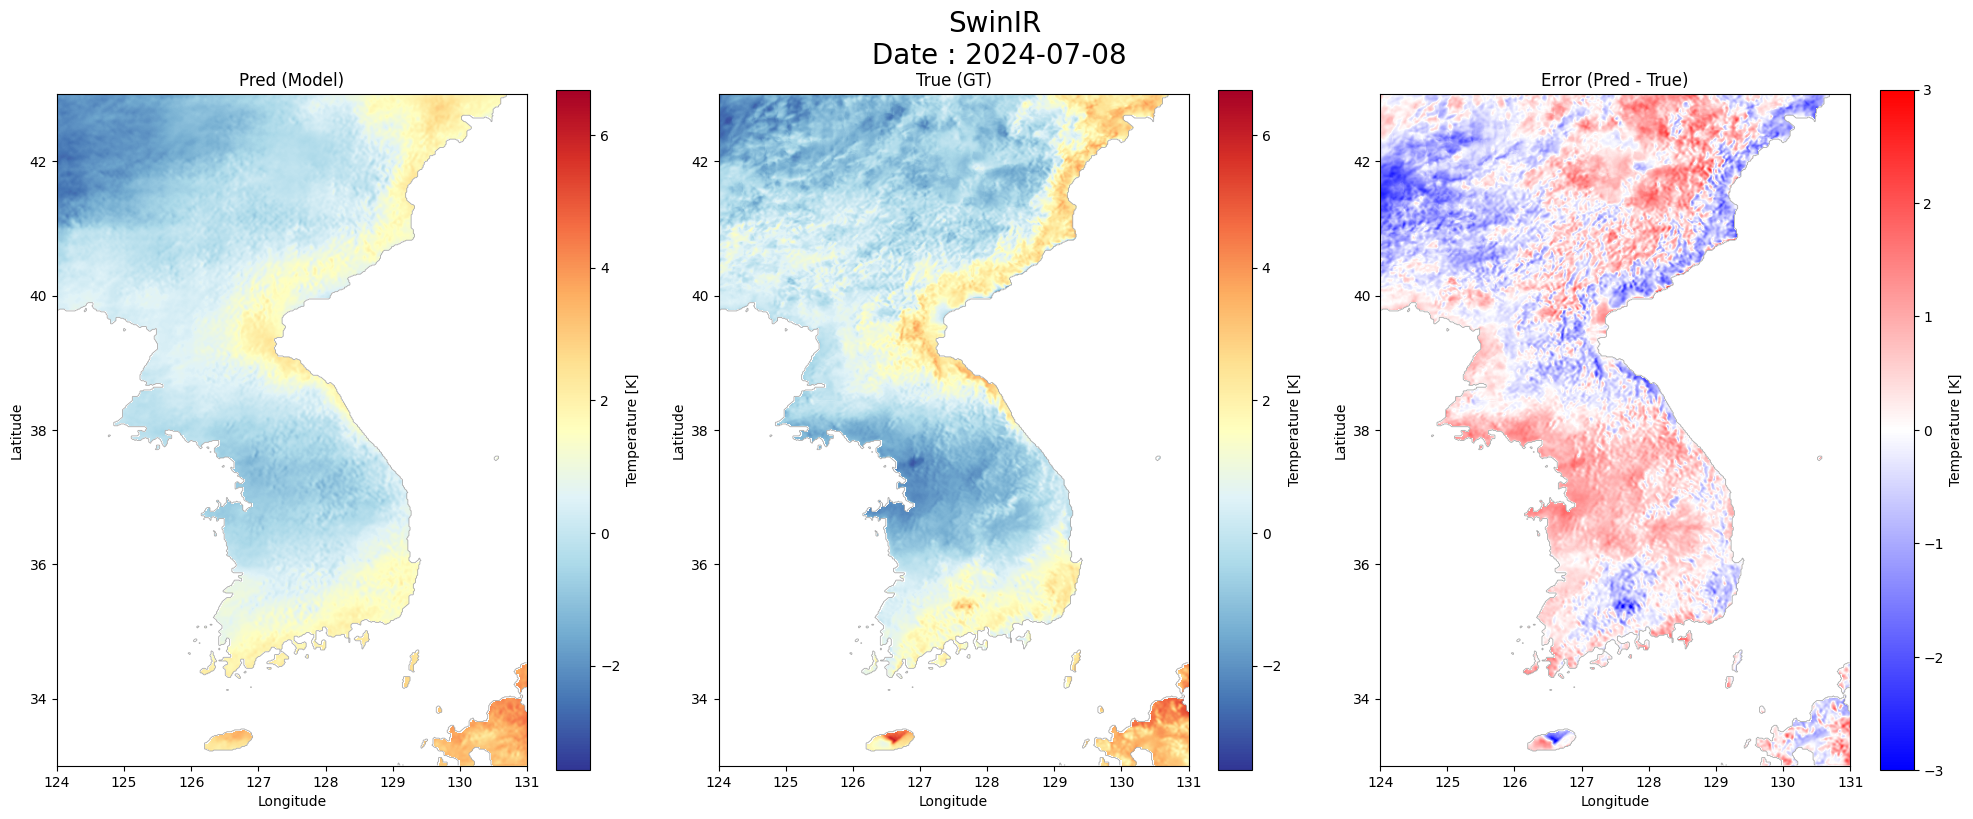

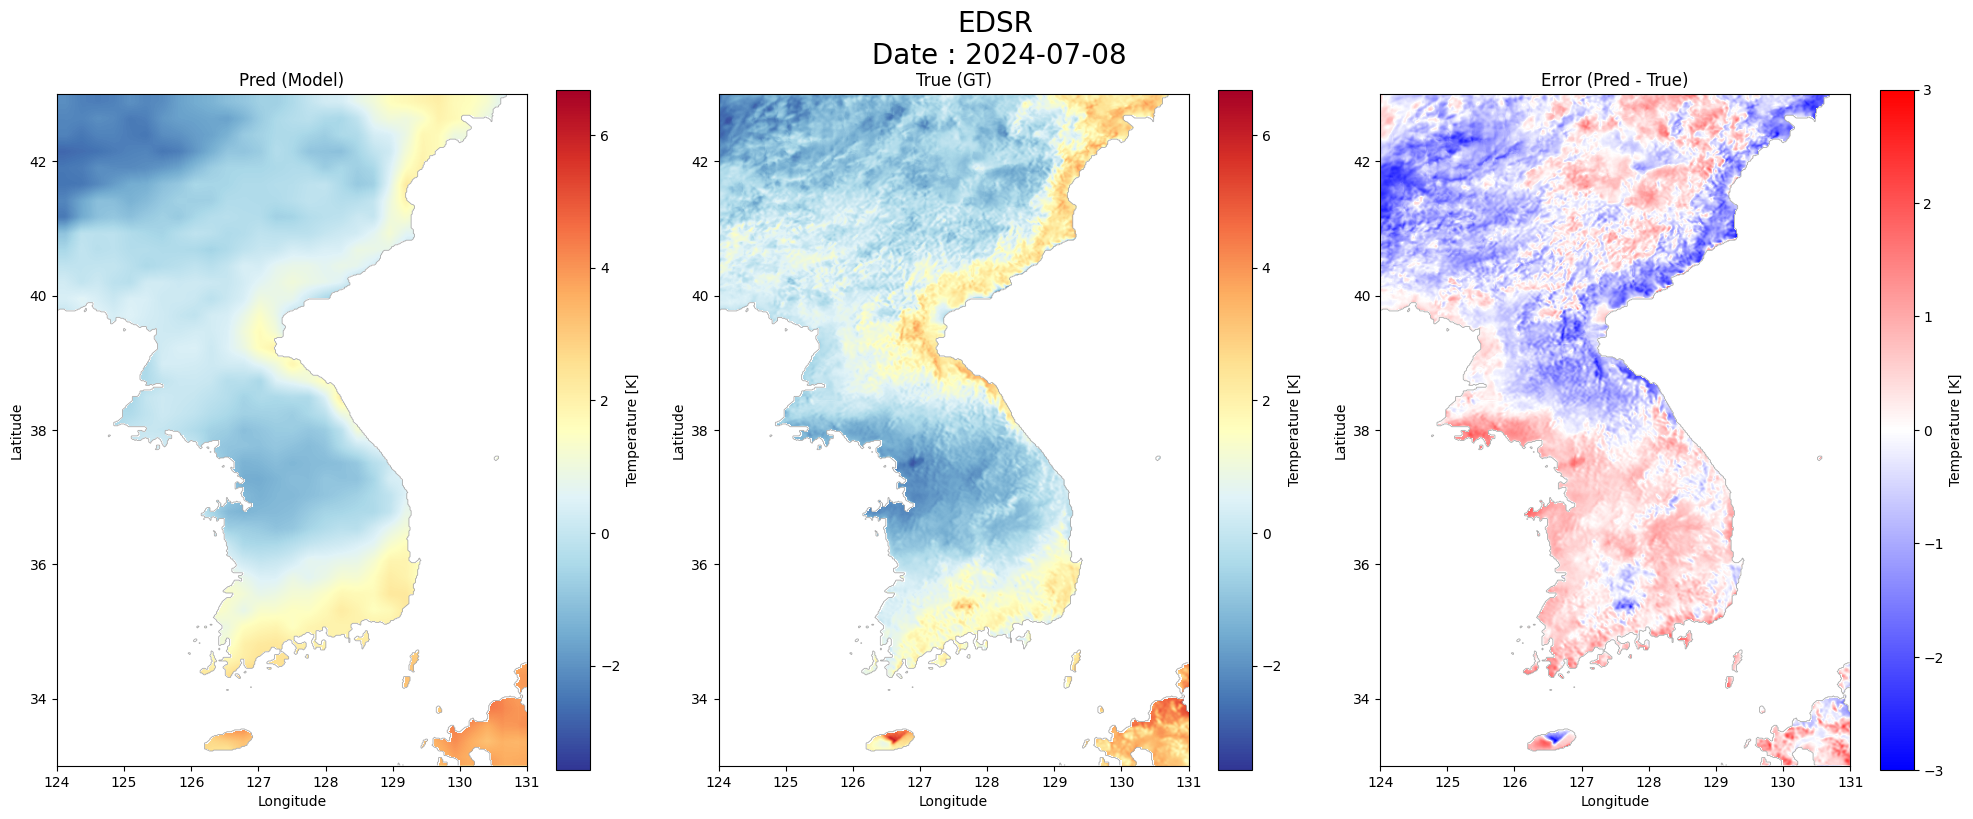

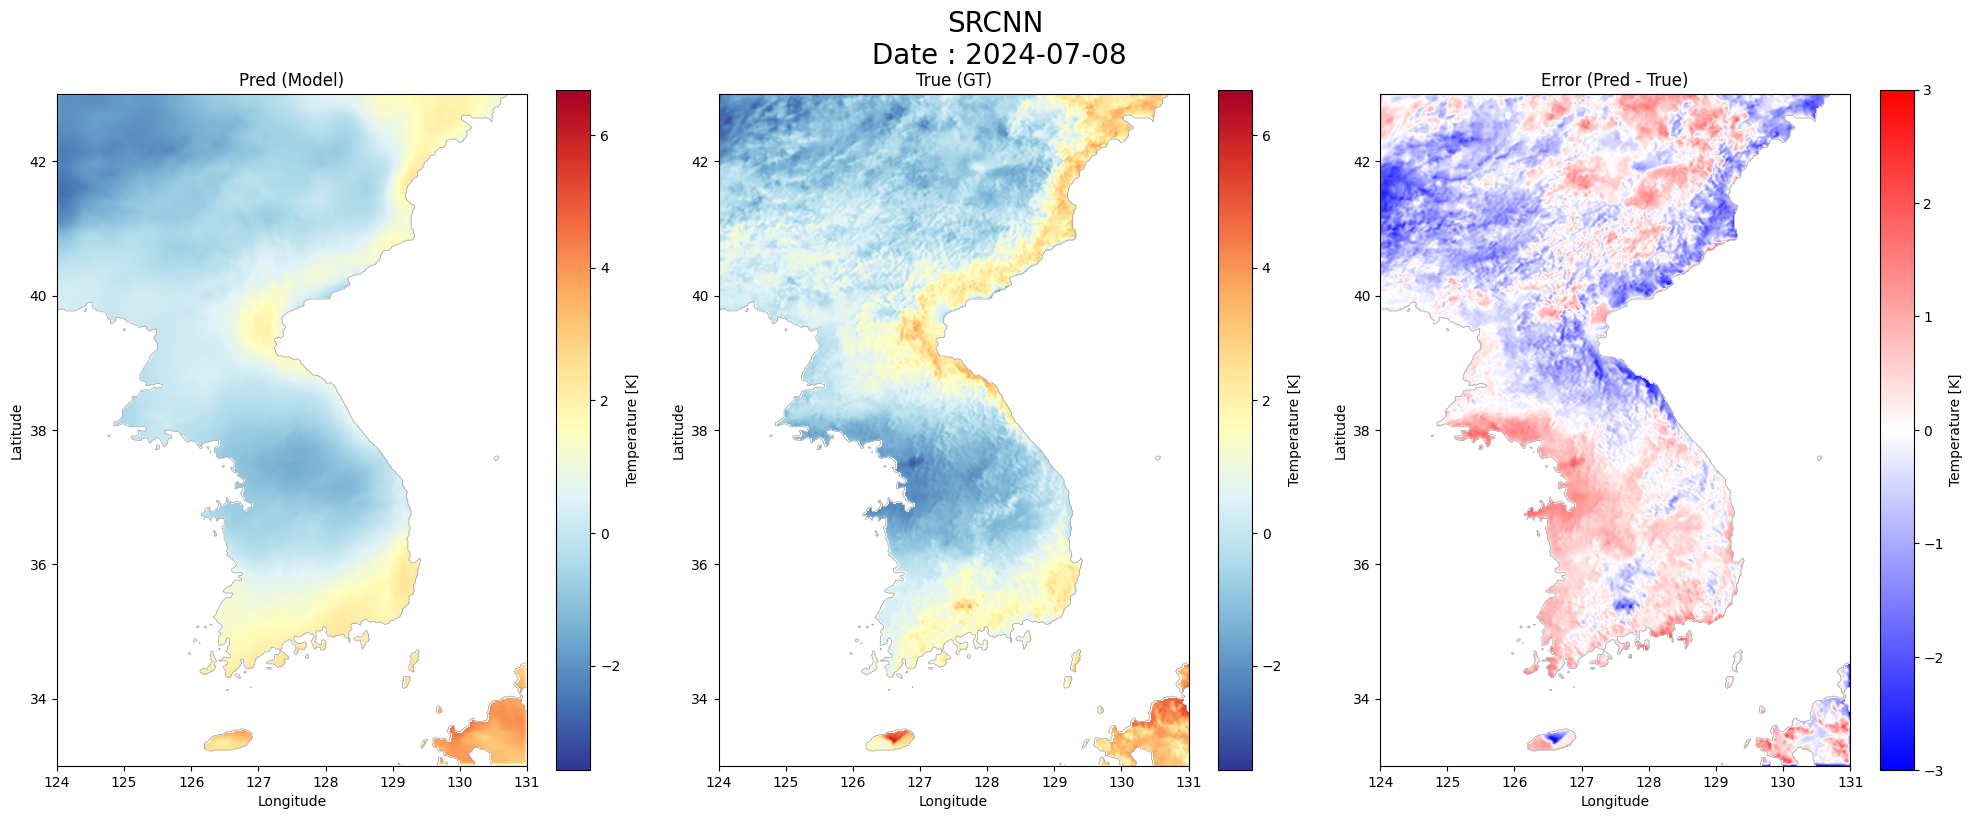

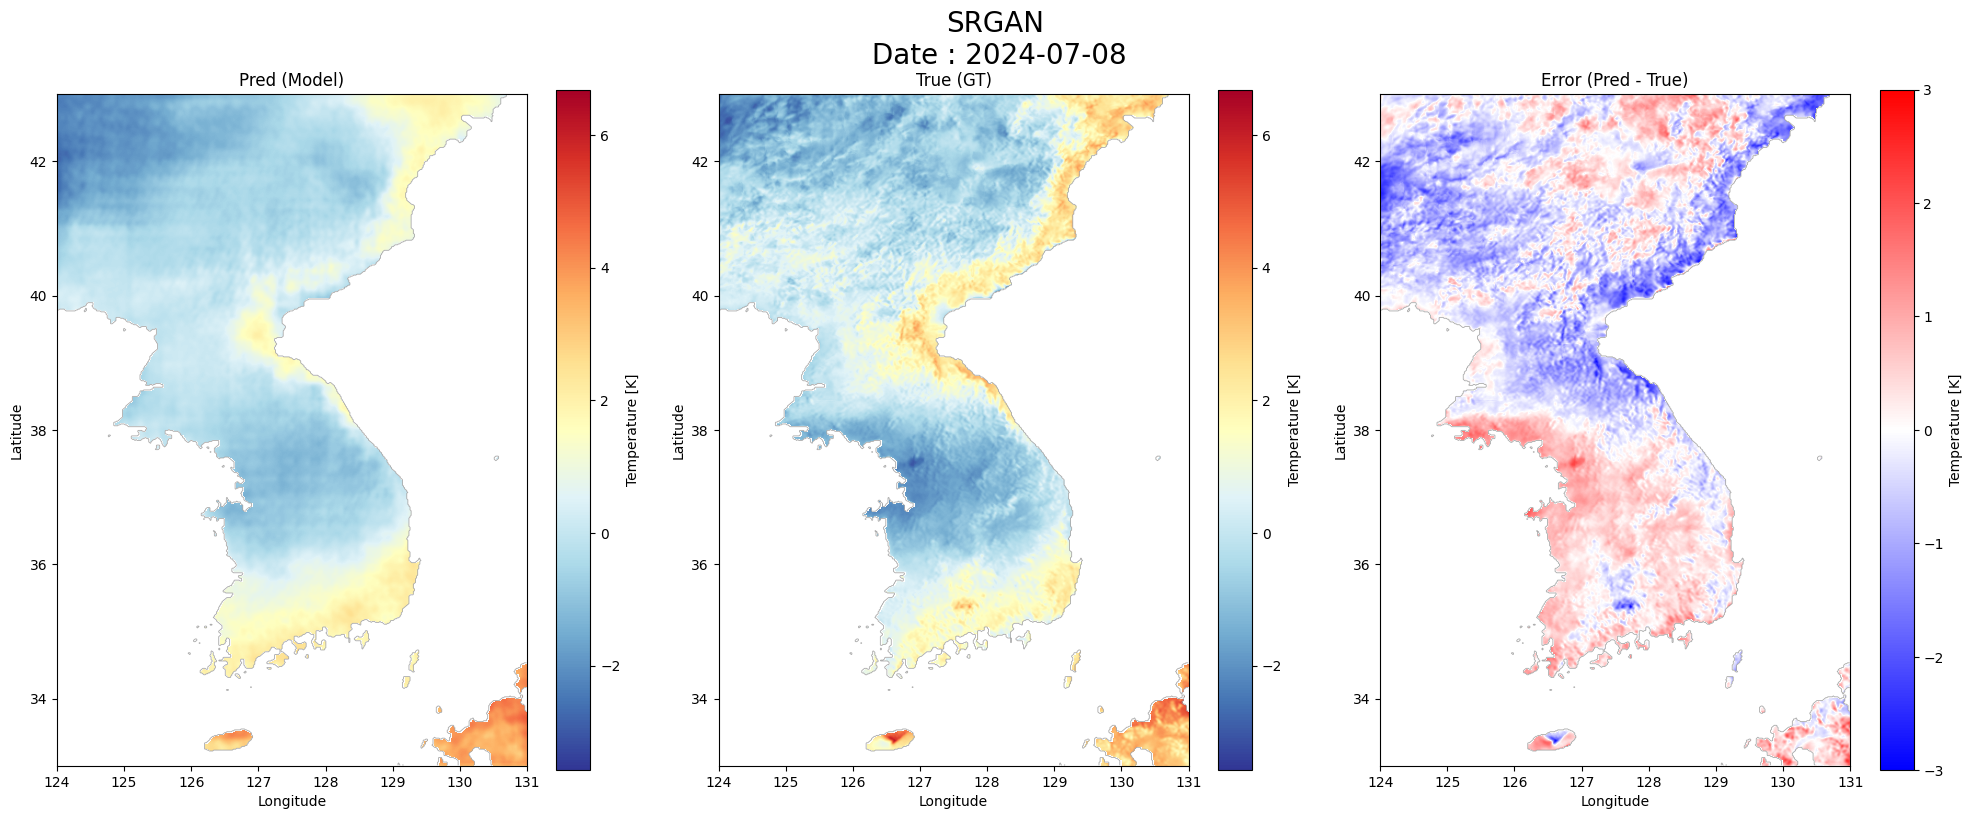

In [11]:
target_date = "2024-07-08"

visualize_snapshot(
    pred=swinir_sdoy,   
    true=true_arr_sdoy,   
    mask=true_arr['mask'],
    dates=dates,
    extent=extent,
    target_date=target_date,
    title=titles[0],
    c_bar=3
)

visualize_snapshot(
    pred=edsr_sdoy,   
    true=true_arr_sdoy,   
    mask=true_arr['mask'],
    dates=dates,
    extent=extent,
    target_date=target_date,
    title=titles[1],
    c_bar=3
)

visualize_snapshot(
    pred=srcnn_sdoy,   
    true=true_arr_sdoy,   
    mask=true_arr['mask'],
    dates=dates,
    extent=extent,
    target_date=target_date,
    title=titles[2],
    c_bar=3

)

visualize_snapshot(
    pred=srgan_sdoy,   
    true=true_arr_sdoy,   
    mask=true_arr['mask'],
    dates=dates,
    extent=extent,
    target_date=target_date,
    title=titles[3],
    c_bar=3
)

## Boxplot (Spatial Corr, SSIM)

In [51]:
def spatial_corr_2d(a2d, b2d, mask2d):
    a = a2d[mask2d]; b = b2d[mask2d]
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < 2: return np.nan
    a = a[ok] - a[ok].mean()
    b = b[ok] - b[ok].mean()
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float((a @ b) / denom) if denom > 0 else np.nan

def ssim_on_mask_scale(a2d, b2d, mask2d):
    a = a2d.copy(); b = b2d.copy()
    a_land = a[mask2d]; b_land = b[mask2d]
    a_fill = np.nanmean(a_land) if np.isfinite(a_land).any() else 0.0
    b_fill = np.nanmean(b_land) if np.isfinite(b_land).any() else 0.0
    a[~mask2d | ~np.isfinite(a)] = a_fill
    b[~mask2d | ~np.isfinite(b)] = b_fill
    mn = min(np.nanmin(a[mask2d]), np.nanmin(b[mask2d]))
    mx = max(np.nanmax(a[mask2d]), np.nanmax(b[mask2d]))
    dr = float(mx - mn) if (mx > mn) and np.isfinite(mx - mn) else 1.0
    return float(ssim(a, b, data_range=dr))



def plot_monthly_boxplots_corr_ssim_scale_with_means(pred_scale, true_scale, mask_bool, dates, title_prefix=""):
    """
    pred_scale, true_scale: (T,H,W)  (×σ_t, K 단위)
    mask_bool: (H,W)
    dates: DatetimeIndex 길이=T
    """
    assert pred_scale.shape == true_scale.shape
    T, H, W = pred_scale.shape
    assert mask_bool.shape == (H, W) and len(dates) == T

    corr = np.full(T, np.nan, np.float32)
    ssimv = np.full(T, np.nan, np.float32)
    for t in range(T):
        corr[t]  = spatial_corr_2d(pred_scale[t], true_scale[t], mask_bool)
        ssimv[t] = ssim_on_mask_scale(pred_scale[t], true_scale[t], mask_bool)

    df = pd.DataFrame({"date": dates, "month": dates.month, "corr": corr, "ssim": ssimv})
    months = np.arange(1, 13)
    month_labels = list("JFMAMJJASOND")  # 1~12월 라벨

    # 월별 평균 계산
    monthly_means_corr = df.groupby("month")["corr"].mean().reindex(months)
    monthly_means_ssim = df.groupby("month")["ssim"].mean().reindex(months)

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

    # --- Corr ---
    data_corr = [df.loc[df["month"] == m, "corr"].dropna().values for m in months]
    axes[0].boxplot(data_corr, positions=months, widths=0.6, showfliers=False)
    axes[0].plot(months, monthly_means_corr.values, marker='o', linewidth=2)   # 월별 평균 라인
    axes[0].set_title(f"{title_prefix} : Pattern Corr ")
    axes[0].set_ylabel("Correlation")
    axes[0].set_xlabel("Month",fontsize=12)
    axes[0].set_ylim(0.7, 1.01)

    # --- SSIM ---
    data_ssim = [df.loc[df["month"] == m, "ssim"].dropna().values for m in months]
    axes[1].boxplot(data_ssim, positions=months, widths=0.6, showfliers=False)
    axes[1].plot(months, monthly_means_ssim.values, marker='o', linewidth=2)   # 월별 평균 라인
    axes[1].set_title(f"{title_prefix} : SSIM ")
    
    axes[1].set_ylim(0.1, 1.01)

    for i in range(2):
        axes[i].grid(True, linestyle='--', alpha=0.5)
        axes[i].set_xlabel("Month",fontsize=12)
        axes[i].set_xticks(months)
        axes[i].set_xticklabels(month_labels,fontsize=11)


    plt.tight_layout(); plt.show()

    print(f"Mean Corr (overall): {np.nanmean(corr):.3f}  |  Mean SSIM (overall): {np.nanmean(ssimv):.3f}")

    return {
        "corr_all": corr,
        "ssim_all": ssimv,
        "monthly_mean_corr": monthly_means_corr,
        "monthly_mean_ssim": monthly_means_ssim,
        "monthly_corr_desc": df.groupby("month")["corr"].describe(),
        "monthly_ssim_desc": df.groupby("month")["ssim"].describe(),
    }


In [ ]:
stats = plot_monthly_boxplots_corr_ssim_scale_with_means(
    pred_scale=swinir_arr["val_scale"],
    true_scale=true_arr["val_scale"],
    mask_bool=true_arr["mask"],
    dates=true_arr["dates"],
    title_prefix="SwinIR"
)


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

# --- 이미 쓰던 함수들 그대로 사용 ---
def spatial_corr_2d(a2d, b2d, mask2d):
    a = a2d[mask2d]; b = b2d[mask2d]
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < 2: return np.nan
    a = a[ok] - a[ok].mean()
    b = b[ok] - b[ok].mean()
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float((a @ b) / denom) if denom > 0 else np.nan

def ssim_on_mask_scale(a2d, b2d, mask2d):
    # 추가 z-score 없이, 마스크 밖/NaN은 각 필드의 육지 평균으로 채움
    a = a2d.copy(); b = b2d.copy()
    a_land = a[mask2d]; b_land = b[mask2d]
    a_fill = np.nanmean(a_land) if np.isfinite(a_land).any() else 0.0
    b_fill = np.nanmean(b_land) if np.isfinite(b_land).any() else 0.0
    a[~mask2d | ~np.isfinite(a)] = a_fill
    b[~mask2d | ~np.isfinite(b)] = b_fill
    mn = min(np.nanmin(a[mask2d]), np.nanmin(b[mask2d]))
    mx = max(np.nanmax(a[mask2d]), np.nanmax(b[mask2d]))
    dr = float(mx - mn) if (mx > mn) and np.isfinite(mx - mn) else 1.0
    return float(ssim(a, b, data_range=dr))

def rmse_masked(A, B, M):
    d = (A - B)[M]
    ok = np.isfinite(d)
    if ok.sum() == 0: return np.nan
    return float(np.sqrt(np.nanmean(d[ok]**2)))

# --- 스냅샷별 4개 지표 계산 (비가중, Bias는 부호 유지) ---
def snapshot_metrics_scale(pred_scale, true_scale, mask_bool, dates=None):
    """
    pred_scale, true_scale: (T,H,W)  // 잔차 패턴 필드 (val_scale)
    mask_bool: (H,W) True=육지
    dates: DatetimeIndex (선택)
    return: DataFrame [date, month, corr, ssim, bias, rmse]
    """
    assert pred_scale.shape == true_scale.shape
    T,H,W = pred_scale.shape
    M = mask_bool.astype(bool)
    rows = []
    for t in range(T):
        P, Tt = pred_scale[t], true_scale[t]
        r   = spatial_corr_2d(P, Tt, M)
        s   = ssim_on_mask_scale(P, Tt, M)
        diff = (P - Tt)[M]
        bias = float(np.nanmean(diff))                # 부호 유지
        rmse = float(np.sqrt(np.nanmean(diff**2)))    # 비가중
        rows.append({"date": None if dates is None else pd.to_datetime(dates[t]),
                     "month": int(dates[t].month) if dates is not None else None,
                     "corr": r, "ssim": s, "bias": bias, "rmse": rmse})
    df = pd.DataFrame(rows)
    if dates is not None:
        df = df.set_index(pd.to_datetime(df["date"])).drop(columns=["date"])
    return df

# --- 월별 박스플롯 + 월평균선 (Corr / SSIM / Bias / RMSE) ---
def plot_monthly_boxplots_4metrics(df_metrics, title_prefix="", ylims=None):
    """
    df_metrics: snapshot_metrics_scale 결과 (index가 날짜이거나 month 컬럼 포함)
    ylims: dict 예) {"corr":(0.6,1.0), "ssim":(0.4,1.0), "bias":(-1.5,1.5), "rmse":(0,2.5)}
    """
    if "month" not in df_metrics.columns:
        # index가 DatetimeIndex라면 month 생성
        if isinstance(df_metrics.index, pd.DatetimeIndex):
            df_metrics = df_metrics.assign(month=df_metrics.index.month)
        else:
            raise ValueError("df_metrics에 'month' 컬럼이 없고, 인덱스가 날짜가 아닙니다.")

    months = np.arange(1, 12+1)
    mlabels = list("JFMAMJJASOND")

    fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=False)

    for ax, key, ylabel, title in [
        (axes[0], "corr", "Correlation", f"{title_prefix} Pattern Corr"),
        (axes[1], "ssim", "SSIM",        f"{title_prefix} SSIM"),
        (axes[2], "bias", "Bias ", f"{title_prefix} Bias "),
        (axes[3], "rmse", "RMSE",        f"{title_prefix} RMSE "),
    ]:
        data = [df_metrics.loc[df_metrics["month"] == m, key].dropna().values for m in months]
        ax.boxplot(data, positions=months, widths=0.6, showfliers=False)
        # 월별 평균선
        monthly_means = df_metrics.groupby("month")[key].mean().reindex(months)
        ax.plot(months, monthly_means.values, marker="o", linewidth=2)
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.set_xticks(months)
        ax.set_xticklabels(mlabels)
        if ylims and key in ylims:
            ax.set_ylim(*ylims[key])

    axes[-1].set_xlabel("Month")
    plt.tight_layout()
    plt.show()

    # 전체 평균 출력
    overall = {k: float(np.nanmean(df_metrics[k])) for k in ["corr","ssim","bias","rmse"]}
    print("Overall means | "
          f"Corr={overall['corr']:.3f}, SSIM={overall['ssim']:.3f}, "
          f"Bias={overall['bias']:.3f}, RMSE={overall['rmse']:.3f}")
    return overall


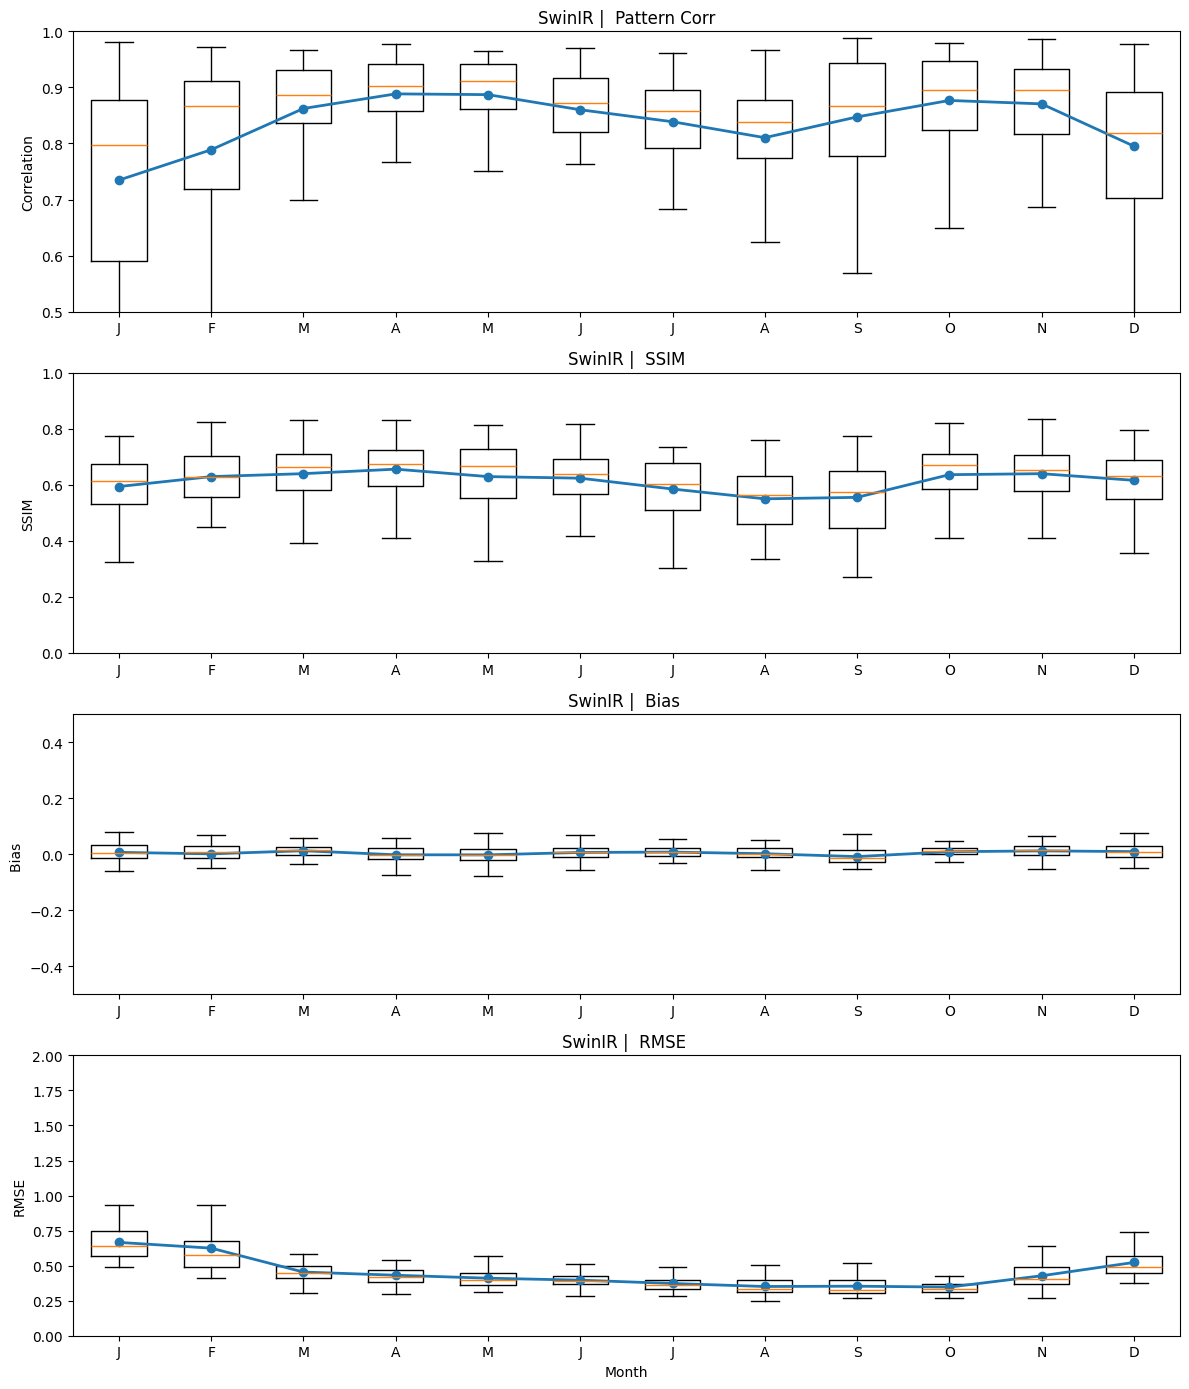

Overall means | Corr=0.838, SSIM=0.613, Bias=0.004, RMSE=0.446


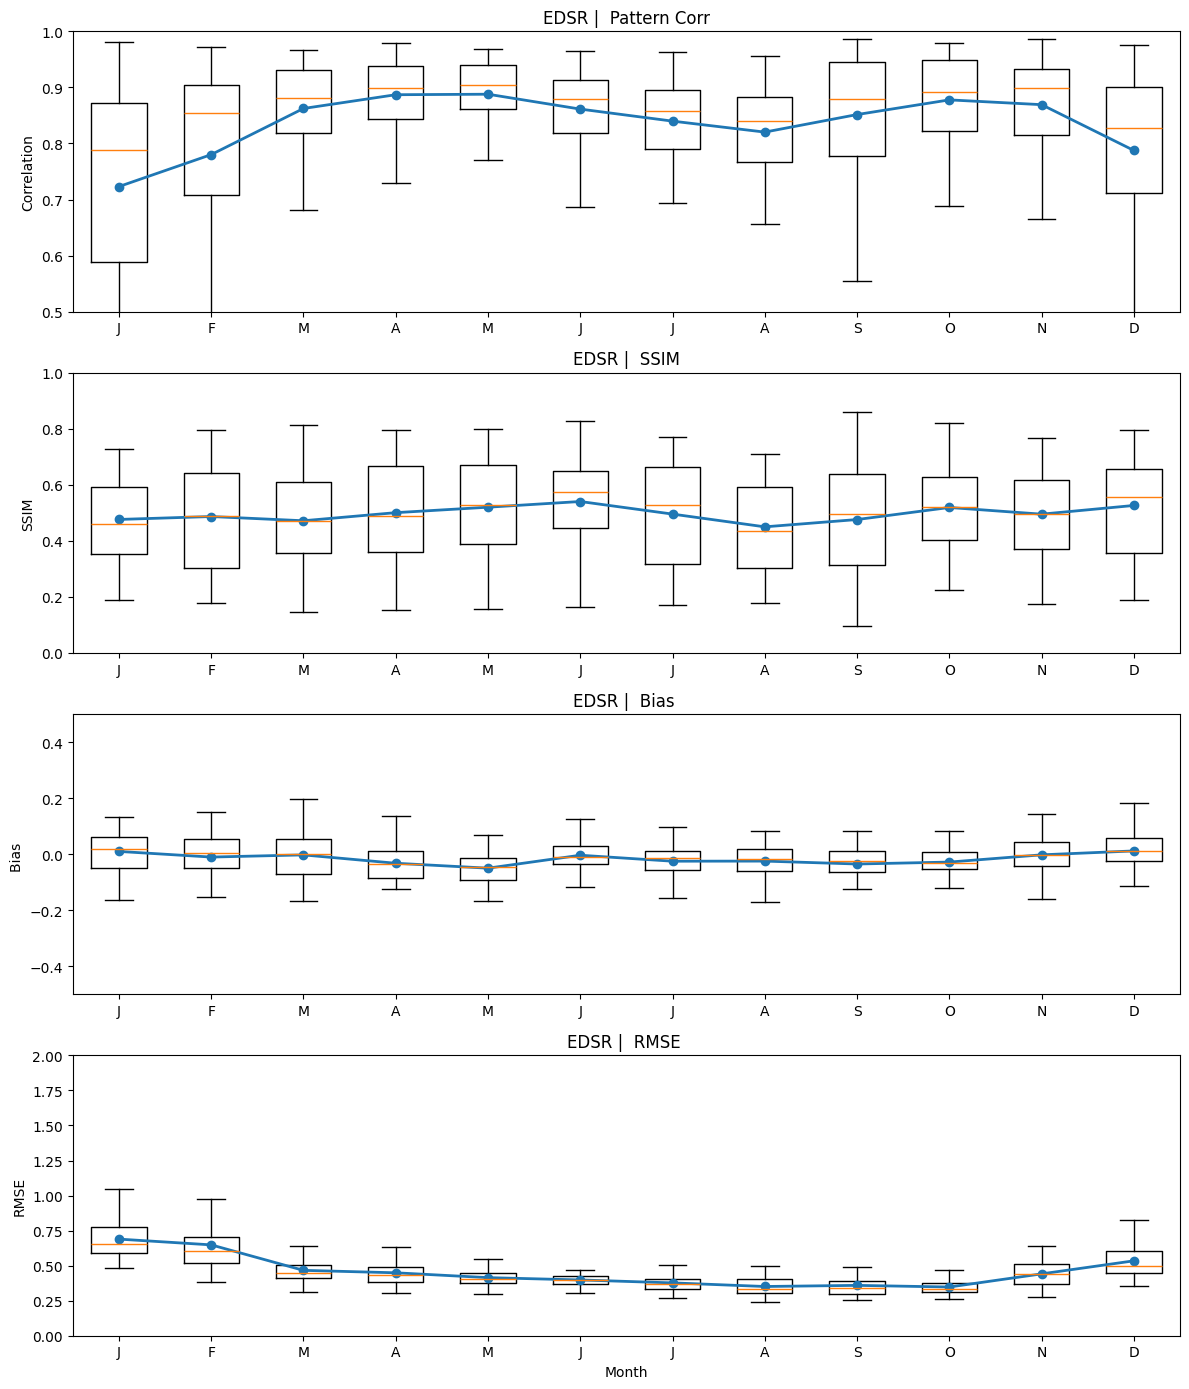

Overall means | Corr=0.837, SSIM=0.497, Bias=-0.016, RMSE=0.456


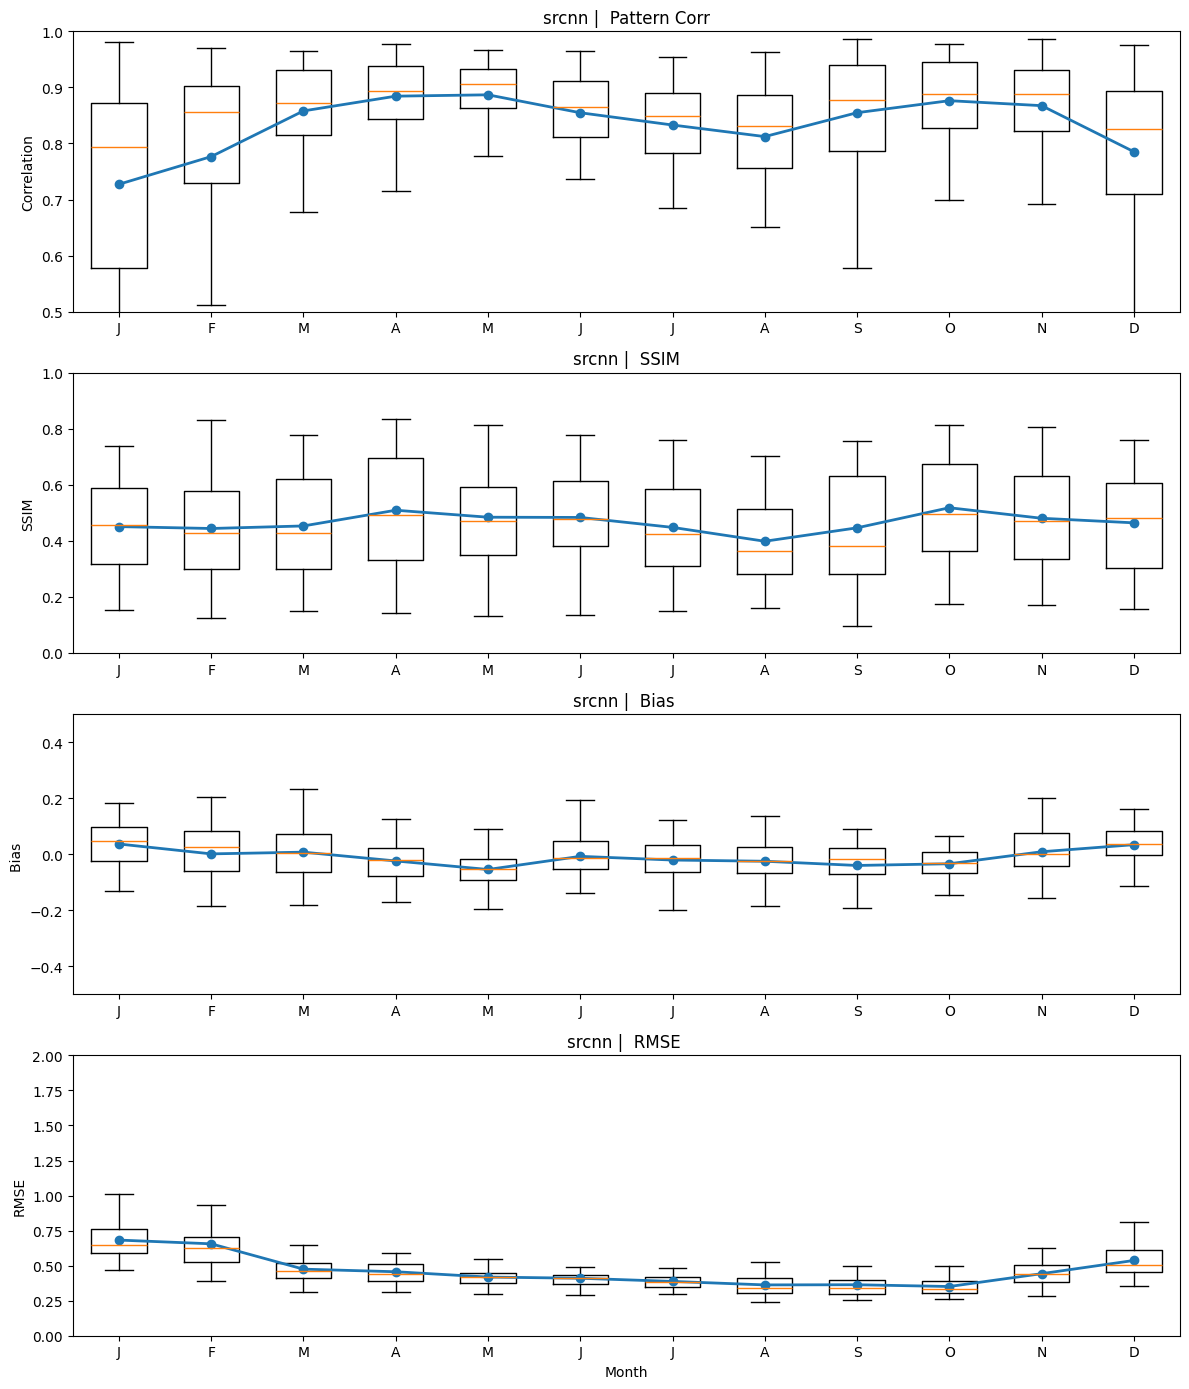

Overall means | Corr=0.835, SSIM=0.465, Bias=-0.010, RMSE=0.461


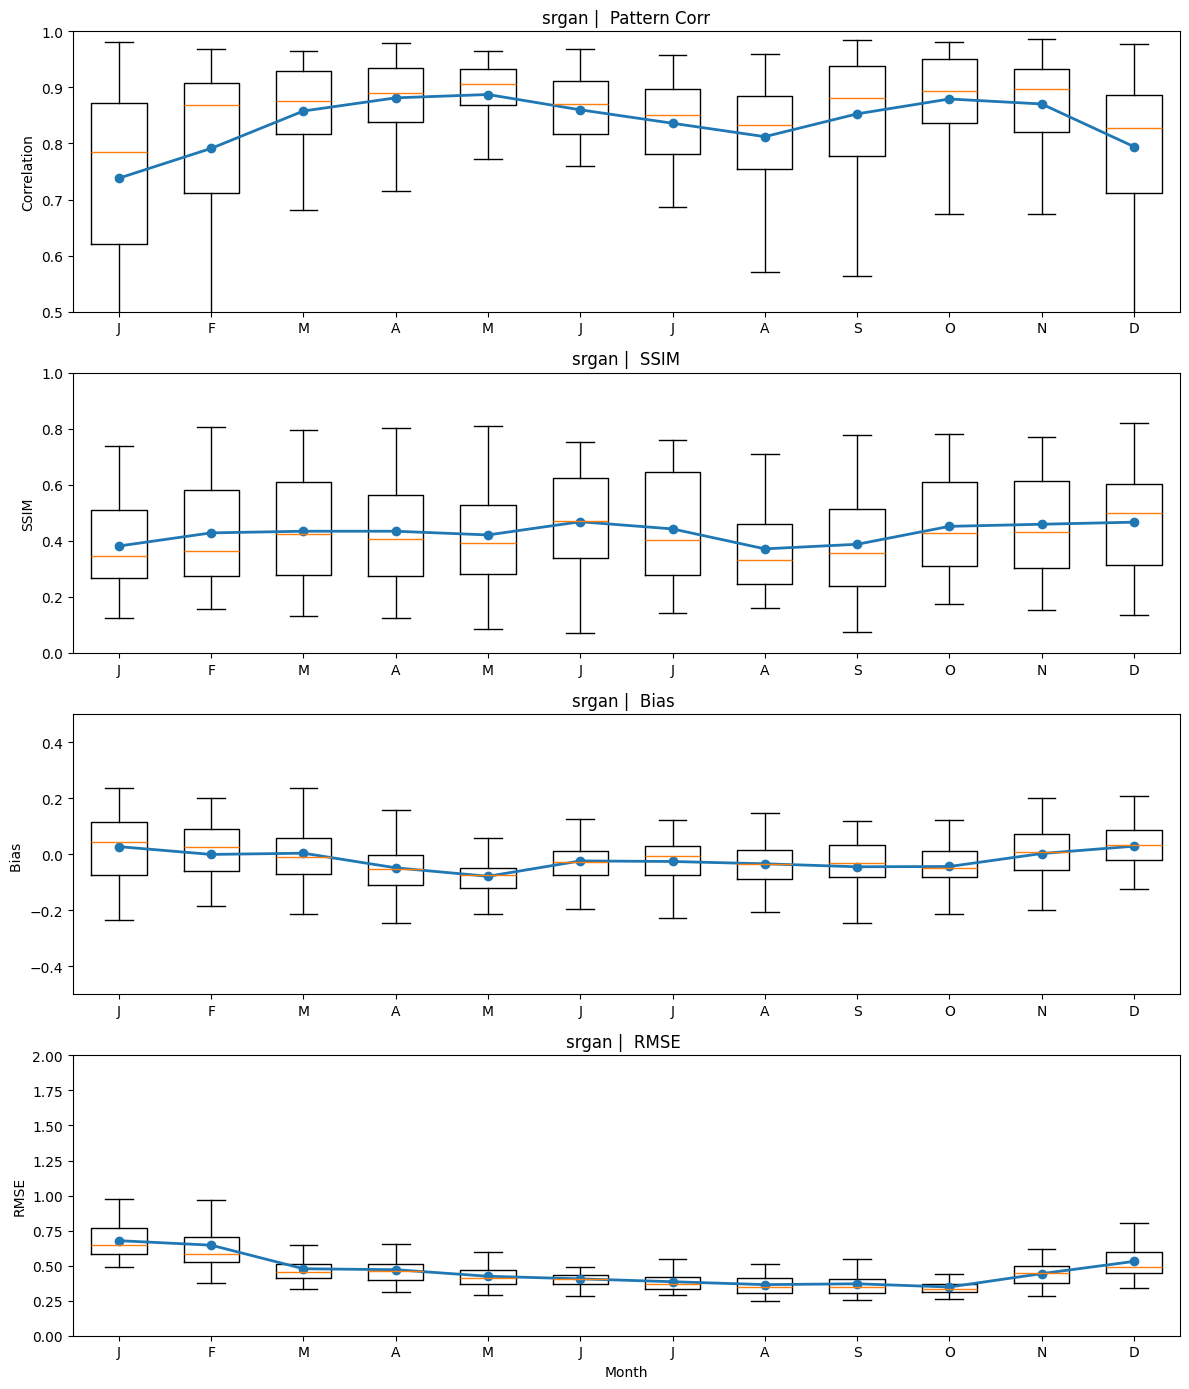

Overall means | Corr=0.838, SSIM=0.429, Bias=-0.020, RMSE=0.461


{'corr': 0.8384284573605872,
 'ssim': 0.4289633169351877,
 'bias': -0.019964395886953257,
 'rmse': 0.4612022694582489}

In [13]:
# 1) 스냅샷별 지표 계산
dfm = snapshot_metrics_scale(swinir_raw, true_arr_raw, true_arr['mask'], dates)

# 2) 4개 지표 월별 박스플롯 그리기
plot_monthly_boxplots_4metrics(
    dfm,
    title_prefix="SwinIR | ",
    ylims={"corr":(0.5,1.0), "ssim":(0,1.0), "bias":(-.5,.5), "rmse":(0,2)}
)



dfm = snapshot_metrics_scale(edsr_raw, true_arr_raw, true_arr['mask'], dates)
plot_monthly_boxplots_4metrics(
    dfm,
    title_prefix="EDSR | ",
    ylims={"corr":(0.5,1.0), "ssim":(0,1.0), "bias":(-.5,.5), "rmse":(0,2)}
)


# 1) 스냅샷별 지표 계산
dfm = snapshot_metrics_scale(srcnn_raw, true_arr_raw, true_arr['mask'], dates)

# 2) 4개 지표 월별 박스플롯 그리기
plot_monthly_boxplots_4metrics(
    dfm,
    title_prefix="srcnn | ",
    ylims={"corr":(0.5,1.0), "ssim":(0,1.0), "bias":(-.5,.5), "rmse":(0,2)}
)



dfm = snapshot_metrics_scale(srgan_raw, true_arr_raw, true_arr['mask'], dates)
plot_monthly_boxplots_4metrics(
    dfm,
    title_prefix="srgan | ",
    ylims={"corr":(0.5,1.0), "ssim":(0,1.0), "bias":(-.5,.5), "rmse":(0,2)}
)



### Snapshot statistcal analysis

In [ ]:
from skimage.metrics import structural_similarity as ssim

# --- 네가 쓰던 헬퍼 재사용 ---
def _normalize_mask(mask, H, W):
    m = np.asarray(mask)
    if m.ndim == 3: m = np.any(m, axis=0)
    if m.ndim == 1 and m.size == H*W: m = m.reshape(H, W)
    if m.shape != (H, W):
        raise ValueError(f"mask shape must be {(H,W)}, got {m.shape}")
    return m.astype(bool)

def spatial_zscore(img2d, mask, eps=1e-8):
    out = img2d.astype(float).copy()
    valid = mask.astype(bool)
    v = out[valid]
    m, s = np.nanmean(v), np.nanstd(v)
    s = max(s, eps)
    out = (out - m) / s
    out[~valid] = np.nan
    return out

def corr_masked(a2d, b2d, mask):
    a = a2d[mask].ravel()
    b = b2d[mask].ravel()
    if a.size < 2:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])

def rmse_masked(a2d, b2d, mask):
    d = (a2d - b2d)[mask].ravel()
    return float(np.sqrt(np.nanmean(d**2)))

# --- 전 기간 스냅샷 지표 계산 (Corr, SSIM, Mean Bias, RMSE) ---
def compute_pattern_metrics_over_time(pred, true, mask, dates, v_pat=(-2, 2)):
    """
    pred, true: (T, H, W)
    mask: (H, W) bool
    dates: DatetimeIndex 또는 변환 가능한 배열
    return: DataFrame [date, month, corr, ssim, mean_bias, rmse]
    """
    if not isinstance(dates, pd.DatetimeIndex):
        dates = pd.to_datetime(dates)

    T, H, W = true.shape if true.ndim == 3 else (1,) + true.shape
    M = _normalize_mask(mask, H, W)

    rows = []
    for t in range(T):
        P = pred[t]; Tt = true[t]

        # 공간 z-score (육지 한정)
        Pz = spatial_zscore(P, M)
        Tz = spatial_zscore(Tt, M)

        # Corr (z-score 필드)
        r = corr_masked(Pz, Tz, M)

        # SSIM (z-score 필드, NaN→0 치환)
        Pz0 = np.nan_to_num(Pz, nan=0.0)
        Tz0 = np.nan_to_num(Tz, nan=0.0)
        dr = np.nanmax(Tz0) - np.nanmin(Tz0)
        dr = dr if np.isfinite(dr) and dr > 0 else 1.0
        ssim_val = float(ssim(Pz0, Tz0, data_range=dr, gaussian_weights=True))

        # 부호 있는 평균 바이어스 / RMSE (원자료 K 단위)
        mean_bias = float(np.nanmean((P - Tt)[M]))
        rmse_val  = rmse_masked(P, Tt, M)

        rows.append({
            "date": dates[t],
            "month": int(dates[t].month),
            "corr": r,
            "ssim": ssim_val,
            "mean_bias": mean_bias,  # 부호 유지
            "rmse": rmse_val
        })

    df = pd.DataFrame(rows).set_index("date").sort_index()
    return df

# --- 여러 모델 한 번에 처리 (모델 이름 붙여서 concat) ---
def compute_metrics_for_models(pred_list, true, mask, dates, model_names):
    dfs = []
    for P, name in zip(pred_list, model_names):
        df = compute_pattern_metrics_over_time(P, true, mask, dates)
        df["model"] = name
        dfs.append(df)
    out = pd.concat(dfs).reset_index().rename(columns={"index": "date"})
    return out  # cols: date, month, corr, ssim, mean_bias, rmse, model

df_metrics = compute_pattern_metrics_over_time(doy_swinir_p2, true_p2, mask, dates)
print(df_metrics.head())

In [ ]:
df_all = compute_metrics_for_models(
    pred2_list,
    true_p2, mask, dates,
    model_names=titles
)

df_all["model"] = pd.Categorical(df_all["model"], categories=titles, ordered=True)
colors = ['royalblue','limegreen','orange','lightcoral']
model_names = df_all["model"].unique()
color_map = dict(zip(model_names, colors))

In [40]:
# 모델별 × 월별 평균/표준편차
monthly_summary = (
    df_all.groupby(["model", "month"])
          .agg(corr_mean=("corr","mean"),   corr_std=("corr","std"),
               ssim_mean=("ssim","mean"),   ssim_std=("ssim","std"),
               bias_mean=("mean_bias","mean"), bias_std=("mean_bias","std"),
               rmse_mean=("rmse","mean"),   rmse_std=("rmse","std"))
          .reset_index()
)
print(monthly_summary)

     model  month  corr_mean  corr_std  ssim_mean  ssim_std  bias_mean  \
0   SwinIR      1   0.755277  0.172326   0.712993  0.069711  -0.162338   
1   SwinIR      2   0.811860  0.165225   0.742911  0.069158  -0.048550   
2   SwinIR      3   0.877747  0.086145   0.766181  0.060925  -0.031600   
3   SwinIR      4   0.887500  0.081586   0.773612  0.057596   0.045904   
4   SwinIR      5   0.887930  0.071250   0.770818  0.052582   0.125719   
5   SwinIR      6   0.868787  0.063424   0.745755  0.046558   0.163214   
6   SwinIR      7   0.825359  0.095213   0.724381  0.051864   0.153945   
7   SwinIR      8   0.812384  0.095939   0.718952  0.044665   0.117855   
8   SwinIR      9   0.857024  0.105945   0.745570  0.072304   0.193901   
9   SwinIR     10   0.866511  0.090051   0.751047  0.061359  -0.033981   
10  SwinIR     11   0.863885  0.100383   0.757730  0.060495  -0.141171   
11  SwinIR     12   0.800130  0.134549   0.729451  0.065984  -0.149111   
12    EDSR      1   0.746970  0.180746

/tmp/ipykernel_3253791/2605164778.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_all.groupby(["model", "month"])


In [ ]:
import matplotlib.pyplot as plt
def plot_monthly_means(df_all, colors=color_map, metric="corr"):
    """
    metric: "corr" | "ssim" | "mean_bias" | "rmse"
    """
    month_labels = [calendar.month_abbr[m][0] for m in range(1, 13)]  # J F M A M J J A S O N D

    plt.figure(figsize=(10, 4))
    for name, grp in df_all.groupby("model"):
        m = grp.groupby("month")[metric].mean()
        plt.plot(m.index, m.values, marker='o', label=name, color=color_map[name], alpha=0.7)
    plt.xticks(range(1,13), month_labels, fontsize=10); plt.xlabel("Month"); plt.ylabel(metric.upper())
    #plt.title(f"{metric} for each month")
    ax = plt.gca()
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5))
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_monthly_box(df_all, colors=colors, metric="corr"):
    """
    각 월에 대해 스냅샷 분포를 박스플롯으로
    """
    plt.figure(figsize=(10, 4))
    for name, grp in df_all.groupby("model"):
        data = [grp[grp["month"]==m][metric].values for m in range(1,13)]
        plt.boxplot(data, positions=np.arange(1,13)-0.15 + 0.3*(list(df_all["model"].unique()).index(name)),
                    widths=0.25)
    plt.xticks(range(1,13)); plt.xlabel("Month"); plt.ylabel(metric)
    plt.title(f"Monthly distribution of {metric}")
    plt.grid(True, alpha=0.3)
    plt.show()

# 예시 호출
plot_monthly_means(df_all, colors=color_map, metric="corr")
plot_monthly_means(df_all, colors=color_map, metric="ssim")
plot_monthly_means(df_all, colors=color_map, metric="mean_bias")
plot_monthly_means(df_all, colors=color_map, metric="rmse")

#plot_monthly_box(df_all, colors=color_map, metric="corr")


#### single model output (monthly snapshot)

In [60]:
import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity as ssim

def compute_pattern_metrics_over_time_single(pred, true, mask, dates):
    """
    pred, true: (T,H,W)
    mask: (H,W) bool
    dates: DatetimeIndex 또는 변환 가능한 배열
    return: DataFrame(index=date) with [month, corr, ssim, mean_bias, rmse]
    """
    if not isinstance(dates, pd.DatetimeIndex):
        dates = pd.to_datetime(dates)

    T, H, W = true.shape if true.ndim == 3 else (1,) + true.shape
    M = _normalize_mask(mask, H, W)

    rows = []
    for t in range(T):
        P = pred[t]; Tt = true[t]

        # 공간 z-score (육지 한정)
        Pz = spatial_zscore(P, M)
        Tz = spatial_zscore(Tt, M)

        # Corr (z-score 필드)
        r = corr_masked(Pz, Tz, M)

        # SSIM (z-score 필드, NaN→0)
        Pz0 = np.nan_to_num(Pz, nan=0.0)
        Tz0 = np.nan_to_num(Tz, nan=0.0)
        dr = np.nanmax(Tz0) - np.nanmin(Tz0)
        dr = dr if np.isfinite(dr) and dr > 0 else 1.0
        ssim_val = float(ssim(Pz0, Tz0, data_range=dr, gaussian_weights=True))

        # 부호 있는 평균 바이어스 / RMSE (K)
        mean_bias = float(np.nanmean((P - Tt)[M]))
        rmse_val  = rmse_masked(P, Tt, M)

        rows.append({
            "date": dates[t],
            "month": int(dates[t].month),
            "corr": r,
            "ssim": ssim_val,
            "mean_bias": mean_bias,
            "rmse": rmse_val
        })

    df = pd.DataFrame(rows).set_index("date").sort_index()
    return df

import matplotlib.pyplot as plt
import numpy as np

def plot_timeseries_metrics_single(df, model_name):
    """Corr/SSIM, Mean bias/RMSE 시간변화 플롯(두 개 그림)."""
    # 1) Corr & SSIM
    plt.figure(figsize=(12, 3.8))
    plt.plot(df.index, df["corr"], label="Corr", linewidth=1.2)
    plt.plot(df.index, df["ssim"], label="SSIM", linewidth=1.2)
    plt.ylabel("Corr / SSIM"); plt.title(f"{model_name} - Time series (Corr & SSIM)")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
    plt.show()

    # 2) Mean bias & RMSE
    fig, ax1 = plt.subplots(figsize=(12, 3.8))
    ax1.plot(df.index, df["mean_bias"], label="Mean bias (K)", linewidth=1.2)
    ax1.axhline(0, color='k', linewidth=0.8, alpha=0.6)
    ax1.set_ylabel("Mean bias [K]")

    ax2 = ax1.twinx()
    ax2.plot(df.index, df["rmse"], label="RMSE (K)", linewidth=1.2, linestyle="--")
    ax2.set_ylabel("RMSE [K]")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    plt.title(f"{model_name} - Time series (Mean bias & RMSE)")
    plt.legend(lines1+lines2, labels1+labels2, loc="upper right")
    plt.grid(alpha=0.3); plt.tight_layout()
    plt.show()

def plot_monthly_summary_single(df, model_name):
    """월별 평균 라인 + 월별 분포 박스플롯(두 개 그림)."""
    # 월별 평균
    g = df.groupby("month").agg(
        corr_mean=("corr","mean"),
        ssim_mean=("ssim","mean"),
        bias_mean=("mean_bias","mean"),
        rmse_mean=("rmse","mean")
    )

    plt.figure(figsize=(10, 3.6))
    plt.plot(g.index, g["corr_mean"], marker='o', label="Corr")
    plt.plot(g.index, g["ssim_mean"], marker='o', label="SSIM")
    plt.xticks(range(1,13)); plt.xlabel("Month"); plt.ylabel("Mean")
    plt.title(f"{model_name} - Monthly means (Corr & SSIM)")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(10, 3.6))
    plt.plot(g.index, g["bias_mean"], marker='o', label="Mean bias [K]")
    plt.plot(g.index, g["rmse_mean"], marker='o', label="RMSE [K]")
    plt.axhline(0, color='k', linewidth=0.8, alpha=0.6)
    plt.xticks(range(1,13)); plt.xlabel("Month"); plt.ylabel("[K]")
    plt.title(f"{model_name} - Monthly means (Bias & RMSE)")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

    # 월별 분포 박스플롯 (Corr/SSIM)
    plt.figure(figsize=(10, 3.6))
    data_corr = [df[df["month"]==m]["corr"].values for m in range(1,13)]
    plt.boxplot(data_corr, positions=np.arange(1,13), widths=0.6, showfliers=False)
    plt.xticks(range(1,13)); plt.xlabel("Month"); plt.ylabel("Corr")
    plt.title(f"{model_name} - Monthly distribution (Corr)"); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    plt.figure(figsize=(10, 3.6))
    data_ssim = [df[df["month"]==m]["ssim"].values for m in range(1,13)]
    plt.boxplot(data_ssim, positions=np.arange(1,13), widths=0.6, showfliers=False)
    plt.xticks(range(1,13)); plt.xlabel("Month"); plt.ylabel("SSIM")
    plt.title(f"{model_name} - Monthly distribution (SSIM)"); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()



def plot_monthly_box_with_mean(df, model_name, metric="corr"):
    """
    df: compute_pattern_metrics_over_time_single() 결과
    model_name: 문자열
    metric: 'mean_bias', 'corr', 'rmse', 'ssim' 중 하나
    """

    month_labels = [calendar.month_abbr[m][0] for m in range(1, 13)]  # J F M A M J J A S O N D

    data = [df[df["month"]==m][metric].values for m in range(1,13)]
    means = [np.nanmean(d) for d in data]  # 월별 평균

    fig, ax = plt.subplots(figsize=(12, 4))
    bp = ax.boxplot(
        data,
        positions=np.arange(1, 13),
        widths=0.6,
        showfliers=False,
        patch_artist=True
    )

    # 박스 색상
    for patch in bp['boxes']:
        patch.set_facecolor('none')   # 내부 채움 제거
        patch.set_alpha(0.6)

    # 평균 점 찍기
    ax.plot(np.arange(1, 13), means, marker='o', color='red', ls='--', markersize=5, label='Mean', alpha=0.5)

    # x축 라벨
    ax.set_xticks(np.arange(1, 13))
    ax.set_xticklabels(month_labels, fontsize=10)
    ax.set_xlabel("Month",fontsize=12)
    ax.set_ylabel(f"{metric.upper()}", fontsize=11)
    ax.set_title(f"{model_name} - snapshot (#: {len(df)})", fontsize=14)
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')

    # mean_bias면 0선 표시
    if metric == "mean_bias":
        ax.axhline(0, color='k', linewidth=0.8, alpha=0.6)

    plt.show()




def show_snapshot_by_stat(df, pred, true, mask, dates, model_name,
                          metric="corr", mode="median", k=3, largest=True,
                          month=None, extent=None, show_affine_error=True, q=None):
    """
    mode: 'median' | 'topk' | 'bottomk' | 'quantile'
      - median: 중앙값 위치 1일
      - topk/bottomk: 상/하위 k일
      - quantile: q(0~1) 분위수에 가장 가까운 1일 (예: q=0.25)
    """
    sub = df if month is None else df[df["month"] == int(month)]
    if sub.empty:
        raise ValueError("선택한 조건에 해당하는 데이터가 없습니다.")

    if mode == "median":
        srt = sub.sort_values(metric)
        idx = (len(srt) - 1) // 2
        dates_pick = [srt.index[idx]]
        tag = f"{metric.upper()} median" + (f" (M{month})" if month else "")
    elif mode in ("topk", "bottomk"):
        srt = sub.sort_values(metric, ascending=not largest)
        dates_pick = list(srt.index[:k])
        tag = f"{metric.upper()} {'top' if largest else 'bottom'} {k}" + (f" (M{month})" if month else "")
    elif mode == "quantile":
        if q is None: q = 0.5
        target = sub[metric].quantile(q)
        # 분위수에 가장 가까운 날짜 1개
        dates_pick = [ (sub[metric]-target).abs().idxmin() ]
        tag = f"{metric.upper()} Q{q:.2f}" + (f" (M{month})" if month else "")
    else:
        raise ValueError("mode must be 'median' | 'topk' | 'bottomk' | 'quantile'.")

    for d in dates_pick:
        visualize_snapshot_pattern(
            pred, true, mask, dates,
            target_date=str(d.date()),
            model_name=f"{model_name} - {tag}",
            extent=extent,
            show_affine_error=show_affine_error
        )



In [ ]:
#df_single = compute_pattern_metrics_over_time_single(swinir_p2, true_p2, mask, dates)
plot_monthly_box_with_mean(df_single, "SwinIR", metric="ssim")
plot_monthly_box_with_mean(df_single, "SwinIR", metric="corr")
plot_monthly_box_with_mean(df_single, "SwinIR", metric="mean_bias")
plot_monthly_box_with_mean(df_single, "SwinIR", metric="rmse")


In [ ]:
# 예시: 단일 모델에 대해
model_name = "SwinIR"

# 전기간 시간변화
plot_timeseries_metrics_single(df_single, model_name)

# 월별 요약/분포
plot_monthly_summary_single(df_single, model_name)



show_snapshot_by_stat(df_single, swinir_p2, true_p2, mask, dates, "SwinIR",
                      metric="corr", mode="median", k=3, largest=False, extent=extent)

# 분위수(예: 25% 지점) 스냅샷 1일
show_snapshot_by_stat(df_single, swinir_p2, true_p2, mask, dates, "SwinIR",
                      metric="corr", mode="quantile", q=0.25, extent=extent)


### RMSE & Corr map

In [ ]:
def compute_monthly_rmse_maps(pred_list, true, dates, mask):
    """
    pred_list, true_list: List of model predictions/targets, each (T, H, W)
    dates: pd.DatetimeIndex of length T
    Returns: (num_models, 12, H, W)
    """
    n_models = len(pred_list)
    rmse_maps_monthly = np.empty((n_models, 12, *pred_list[0].shape[1:]))

    for i in range(n_models):
        for m in range(1, 13):
            idx = np.where(dates.month == m)[0]
            pred = pred_list[i][idx]
            true = true[idx]

            bias = np.nanmean(pred - true, axis=0)
            residual = (pred - true) - bias
            rmse = np.sqrt(np.nanmean(residual ** 2, axis=0))
            rmse[~mask] = np.nan
            rmse_maps_monthly[i, m - 1] = rmse

    return rmse_maps_monthly
def plot_rmse_maps_monthly(rmse_maps, mask, extent, titles=None):
    fig, axs = plt.subplots(4, 12, figsize=(24, 10), constrained_layout=True)
    month_names = [f"{m:02d}" for m in range(1, 13)]

    for i in range(4):
        for j in range(12):
            rmse = rmse_maps[i, j]
            mean_rmse = np.nanmean(rmse)
            model_title = titles[i] if titles else f"Model {i+1}"
            ax = axs[i, j]

            im = ax.imshow(rmse, cmap="magma_r", vmin=0.5, vmax=4,
                           extent=extent, origin="lower")
            ax.contour(mask, levels=[0.5], colors='darkgrey', linewidths=0.4,
                       extent=extent, origin='lower')

            if i == 0:
                ax.set_title(f"{month_names[j]}", fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{model_title}", fontsize=10)

            ax.text(0.5, 0.11, f"Mean RMSE = {mean_rmse:.2f} K", fontsize=8,
                    transform=ax.transAxes, ha='center', va='center')

    plt.show()

# 월별 RMSE 계산
rmse_maps_monthly = compute_monthly_rmse_maps(pred_list, true_list, dates, mask)

# 시각화
plot_rmse_maps_monthly(rmse_maps_monthly, mask, extent, titles=titles)

In [16]:
from matplotlib.patches import Rectangle
rect = Rectangle((124, 33), 6, 5, linewidth=1.2, edgecolor='blue', facecolor='none', linestyle='--')

def rmse_corr_KOR(rmse_map, corr_map, mask=mask, extent=extent):
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    lon_min, lon_max, lat_min, lat_max = extent
    ny, nx = rmse_map.shape

    # grid edge for pcolormesh
    lats = np.linspace(lat_min, lat_max, ny + 1)
    lons = np.linspace(lon_min, lon_max, nx + 1)

    # grid center for masking & contour
    latc = np.linspace(lat_min, lat_max, ny)
    lonc = np.linspace(lon_min, lon_max, nx)
    lat_grid, lon_grid = np.meshgrid(latc, lonc, indexing="ij")

    # 전체 평균
    mean_rmse_all = np.nanmean(rmse_map)
    mean_corr_all = np.nanmean(corr_map)

    # 남한만 마스킹 (위도 38도 이상, 또는 33~35 & 129~131)
    invalid_mask = (lat_grid >= 38) | ((lat_grid >= 33) & (lat_grid <= 35) & (lon_grid >= 129) & (lon_grid <= 131))
    rmse_masked = np.where(invalid_mask, np.nan, rmse_map)
    corr_masked = np.where(invalid_mask, np.nan, corr_map)

    mean_rmse_kor = np.nanmean(rmse_masked)
    mean_corr_kor = np.nanmean(corr_masked)

    # Plot RMSE
    im0 = axs[0].pcolormesh(lons, lats, rmse_map, cmap="magma_r", shading="auto", vmin= 0., vmax=2.0)
    axs[0].set_title(f"RMSE Map")
    axs[0].text(0.02, 0.11, f"All = {mean_rmse_all:.3f}", transform=axs[0].transAxes, fontsize=10, color="black")
    axs[0].text(0.02, 0.05, f"KOR = {mean_rmse_kor:.3f}", transform=axs[0].transAxes, fontsize=10, color="black")
    plt.colorbar(im0, ax=axs[0], label="Temperature [K]")

    # Plot Corr
    im1 = axs[1].pcolormesh(lons, lats, corr_map, cmap="OrRd", vmin= 0.9, vmax=1, shading="auto")
    axs[1].set_title(f"Correlation Map")
    axs[1].text(0.02, 0.11, f"ALL = {mean_corr_all:.3f}", transform=axs[1].transAxes, fontsize=10, color="black")
    axs[1].text(0.02, 0.05, f"KOR = {mean_corr_kor:.3f}", transform=axs[1].transAxes, fontsize=10, color="black")
    plt.colorbar(im1, ax=axs[1])

    # South Korea 영역 박스
    # for ax in axs:
    #     ax.add_patch(rect)
    #     ax.contour(lon_grid, lat_grid, mask, levels=[0.5], colors='darkgrey', linewidths=0.4)
    #     ax.set_xlabel("Longitude")
    #     ax.set_ylabel("Latitude")

    #plt.tight_layout()
    plt.show()

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# RMSE 시각화
def plot_rmse_maps(rmse_maps, mask, titles=None, extent=None):
    fig, axs = plt.subplots(1, len(rmse_maps), figsize=(4.5*len(rmse_maps), 5))
    for i in range(len(rmse_maps)):
        rmse_mapp = rmse_maps[i]
        mean_rmse = np.nanmean(rmse_mapp)
        title = titles[i] if titles else f"Model {i+1}"

        im = axs[i].imshow(rmse_mapp, cmap="magma_r", extent=extent, origin="lower",vmin=0, vmax=2.0)
        axs[i].set_title(f"{title}", fontsize=10)
        axs[i].contour(mask, levels=[0.5], colors="darkgrey", linewidths=0.4,
                       extent=extent, origin="lower")
        axs[i].set_xlabel("Longitude")

        axs[i].text(0.5, 0.11, rf"$\mathrm{{RMSE}}_{{\mathrm{{mean}}}}$ = {mean_rmse:.3f}",
                    fontsize=8, transform=axs[i].transAxes,
                    ha="center", va="center")
        if i == 0:
            axs[i].set_ylabel("Latitude")

    fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.92, label="RMSE")
    plt.show()


# Correlation 시각화
def plot_corr_maps(corr_maps, mask, titles=None, extent=None):
    fig, axs = plt.subplots(1, len(corr_maps), figsize=(4.5*len(corr_maps), 5))
    for i in range(len(corr_maps)):
        corr_mapp = corr_maps[i]
        mean_corr = np.nanmean(corr_mapp)
        title = titles[i] if titles else f"Model {i+1}"

        im = axs[i].imshow(corr_mapp, cmap="OrRd", extent=extent, origin="lower",
                           vmin=0.9, vmax=1.0)
        axs[i].set_title(f"{title}", fontsize=10)
        axs[i].contour(mask, levels=[0.5], colors="darkgrey", linewidths=0.4,
                       extent=extent, origin="lower")
        axs[i].set_xlabel("Longitude")

        axs[i].text(0.5, 0.11, rf"$\mathrm{{Corr}}_{{\mathrm{{mean}}}}$ = {mean_corr:.3f}",
                    fontsize=8, transform=axs[i].transAxes,
                    ha="center", va="center")
        if i == 0:
            axs[i].set_ylabel("Latitude")

    fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.92, label="Correlation")
    plt.show()


In [ ]:
# rmse_p_edsr = fast_gridwise_rmse(edsr_p, true_p, mask); corr_p_edsr = fast_gridwise_corr(edsr_p, true_p, mask)
# rmse_p_cnn = fast_gridwise_rmse(srcnn_p, true_p, mask); corr_p_cnn = fast_gridwise_corr(srcnn_p, true_p, mask)
# rmse_p_gan = fast_gridwise_rmse(gan_p, true_p, mask); corr_p_gan = fast_gridwise_corr(gan_p, true_p, mask)
# rmse_p_IR = fast_gridwise_rmse(swinir_p, true_p, mask); corr_p_IR = fast_gridwise_corr(swinir_p, true_p, mask)

rmse_p2_edsr = fast_gridwise_rmse(edsr_p2, true_p2, mask); corr_p2_edsr = fast_gridwise_corr(edsr_p2, true_p2, mask)
rmse_p2_cnn = fast_gridwise_rmse(srcnn_p2, true_p2, mask); corr_p2_cnn = fast_gridwise_corr(srcnn_p2, true_p2, mask)
rmse_p2_gan = fast_gridwise_rmse(gan_p2, true_p2, mask); corr_p2_gan = fast_gridwise_corr(gan_p2, true_p2, mask)
rmse_p2_IR = fast_gridwise_rmse(swinir_p2, true_p2, mask); corr_p2_IR = fast_gridwise_corr(swinir_p2, true_p2, mask)



# rmse_corr_KOR(rmse_p2_IR, corr_p2_IR)
# rmse_corr_KOR(rmse_p2_edsr, corr_p2_edsr)
# rmse_corr_KOR(rmse_p2_cnn, corr_p2_cnn)
# rmse_corr_KOR(rmse_p2_gan, corr_p2_gan)

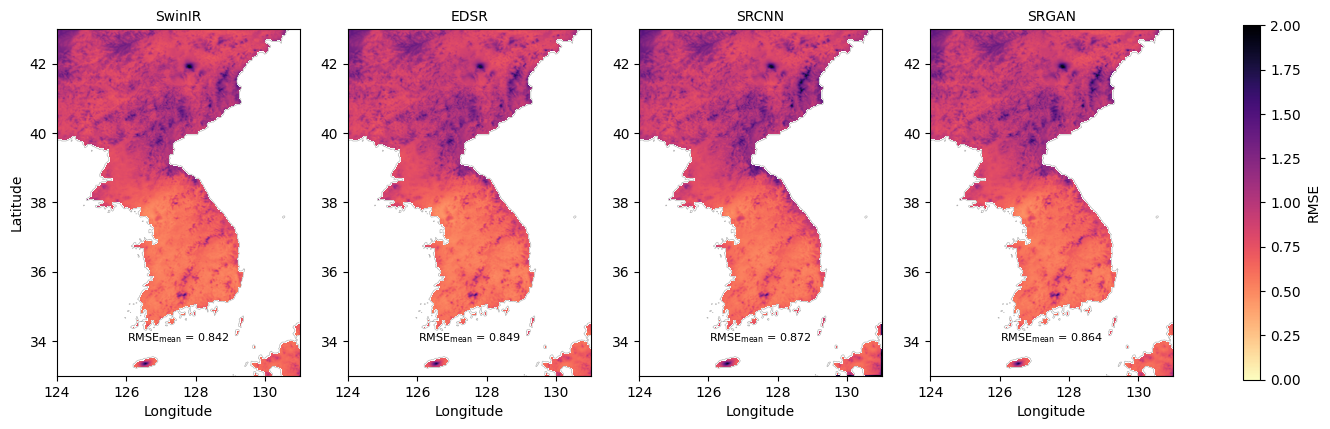

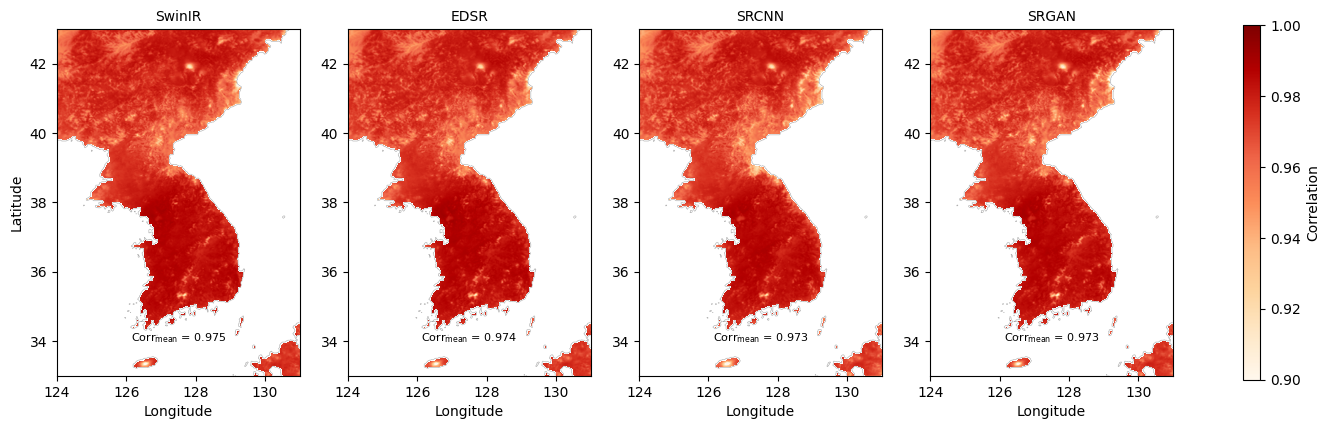

In [23]:
rmse_map_list=[rmse_p2_IR,rmse_p2_edsr,rmse_p2_cnn,rmse_p2_gan]
corr_map_list=[corr_p2_IR,corr_p2_edsr,corr_p2_cnn,corr_p2_gan]

plot_rmse_maps(rmse_map_list, mask, titles=titles, extent=extent)
plot_corr_maps(corr_map_list, mask, titles=titles, extent=extent)

#### Pattern correlation with Elevation

In [ ]:
import numpy as np
from scipy.stats import pearsonr, spearmanr

def pattern_corr(a2d, b2d, mask=None, method="pearson"):
    """
    a2d, b2d : (H, W) numpy arrays
    mask     : (H, W) bool, True=사용할 픽셀. None이면 전체 사용
    method   : "pearson" or "spearman"
    return   : (r, p, n)  # 상관계수, p-value, 사용한 픽셀 수
    """
    if a2d.shape != b2d.shape:
        raise ValueError(f"shape mismatch: {a2d.shape} vs {b2d.shape}")

    # 기본 유효 마스크 (둘 다 finite)
    valid = np.isfinite(a2d) & np.isfinite(b2d)
    if mask is not None:
        if mask.shape != a2d.shape:
            raise ValueError(f"mask shape mismatch: {mask.shape} vs {a2d.shape}")
        valid &= mask

    x = a2d[valid].ravel()
    y = b2d[valid].ravel()
    n = x.size

    if n < 3:
        return np.nan, np.nan, n

    if method.lower() == "pearson":
        r, p = pearsonr(x, y)
    elif method.lower() == "spearman":
        r, p = spearmanr(x, y)
    else:
        raise ValueError("method must be 'pearson' or 'spearman'")

    return float(r), float(p), int(n)

# ---------- 사용 예시 ----------
# rmse_map: (H,W) nRMSE or RMSE
# elev_map: (H,W) elevation
# landmask: (H,W) True=land
# Pearson

elev_tensor = torch.load("../Data/Dataset/input_elevation_data.pt", map_location="cpu")

# (H,W)로 변환 + numpy
if elev_tensor.ndim == 3:
    elev_map = elev_tensor.squeeze(0).numpy()
else:
    elev_map = elev_tensor.numpy()


r_p, p_p, n = pattern_corr(rmse_p3_IR, elev_map, mask=mask, method="pearson")
print(f"MAE model - Pattern corr (Pearson): r={r_p:.3f}, p={p_p:.3g}, n={n}")

r_p, p_p, n = pattern_corr(old_rmse_p3_IR, elev_map, mask=mask, method="pearson")
print(f"MSE model -  Pattern corr (Pearson): r={r_p:.3f}, p={p_p:.3g}, n={n}")

# Spearman (선택)
r_s, p_s, _ = pattern_corr(rmse_p3_IR, elev_map, mask=mask, method="spearman")
print(f"MAE model - Pattern corr (Spearman): r={r_s:.3f}, p={p_s:.3g}")
r_s, p_s, _ = pattern_corr(old_rmse_p3_IR, elev_map, mask=mask, method="spearman")
print(f"MSE model -  Pattern corr (Spearman): r={r_s:.3f}, p={p_s:.3g}")

torch.Size([731, 430])


/tmp/ipykernel_3889571/3275110660.py:85: RuntimeWarning: Mean of empty slice
  rmse_map = np.sqrt(np.nanmean(error_sq, axis=0))  # (H, W)
/tmp/ipykernel_3889571/3275110660.py:69: RuntimeWarning: Mean of empty slice
  pred_mean = np.nanmean(pred, axis=0)
/tmp/ipykernel_3889571/3275110660.py:70: RuntimeWarning: Mean of empty slice
  true_mean = np.nanmean(true, axis=0)


MAE model - Pattern corr (Pearson): r=0.487, p=0, n=140411
MSE model -  Pattern corr (Pearson): r=0.487, p=0, n=140411
MAE model - Pattern corr (Spearman): r=0.509, p=0
MSE model -  Pattern corr (Spearman): r=0.511, p=0


### Times series comparision (with station)

In [61]:
stations = {
    "Seoul": (37.57142, 126.9658),
    "Busan": (35.10468, 129.03203),
    "Daegu": (35.87797, 128.65296),
    "Daejeon": (36.37199, 127.3721),
    "Gwangju": (35.17294, 126.89156),
}

# 위경도를 인덱스로 변환
def find_nearest_index(arr, value):
    return np.abs(arr - value).argmin()

station_indices = {}
for name, (lat_val, lon_val) in stations.items():
    distance = (lat - lat_val)**2 + (lon - lon_val)**2
    iy, ix = np.unravel_index(np.argmin(distance), distance.shape)
    station_indices[name] = (iy, ix)

# 결과 확인
for name, (y, x) in station_indices.items():
    print(f"{name} nearest grid: lat: {lat[y,x]:.4f}, lon: {lon[y,x]:.4f}")

Seoul nearest grid: lat: 37.5768, lon: 126.9662
Busan nearest grid: lat: 35.1069, lon: 129.0308
Daegu nearest grid: lat: 35.8750, lon: 128.6585
Daejeon nearest grid: lat: 36.3699, lon: 127.3765
Gwangju nearest grid: lat: 35.1772, lon: 126.8973


In [62]:
df = pl.read_csv("../Data/ASOS_daily_2023-2024.csv", encoding="euc-kr")
cities = ["서울", "부산", "대구", "대전", "광주"]
name_map = {
    "서울": "Seoul",
    "부산": "Busan",
    "대구": "Daegu",
    "대전": "Daejeon",
    "광주": "Gwangju"
}

selected = (
    df
    .filter(pl.col("지점명").is_in(cities))
    .select(["지점명", "일시", "평균기온(°C)"])
    .with_columns(
        pl.col("일시").str.strptime(pl.Date, "%Y-%m-%d").alias("date"))
)


for station in cities:
    station_df = selected.filter(pl.col("지점명") == station).select(["date", "평균기온(°C)"])

    dates = station_df["date"].to_numpy()
    temps = station_df["평균기온(°C)"].to_numpy()
    eng_name = name_map.get(station, station)

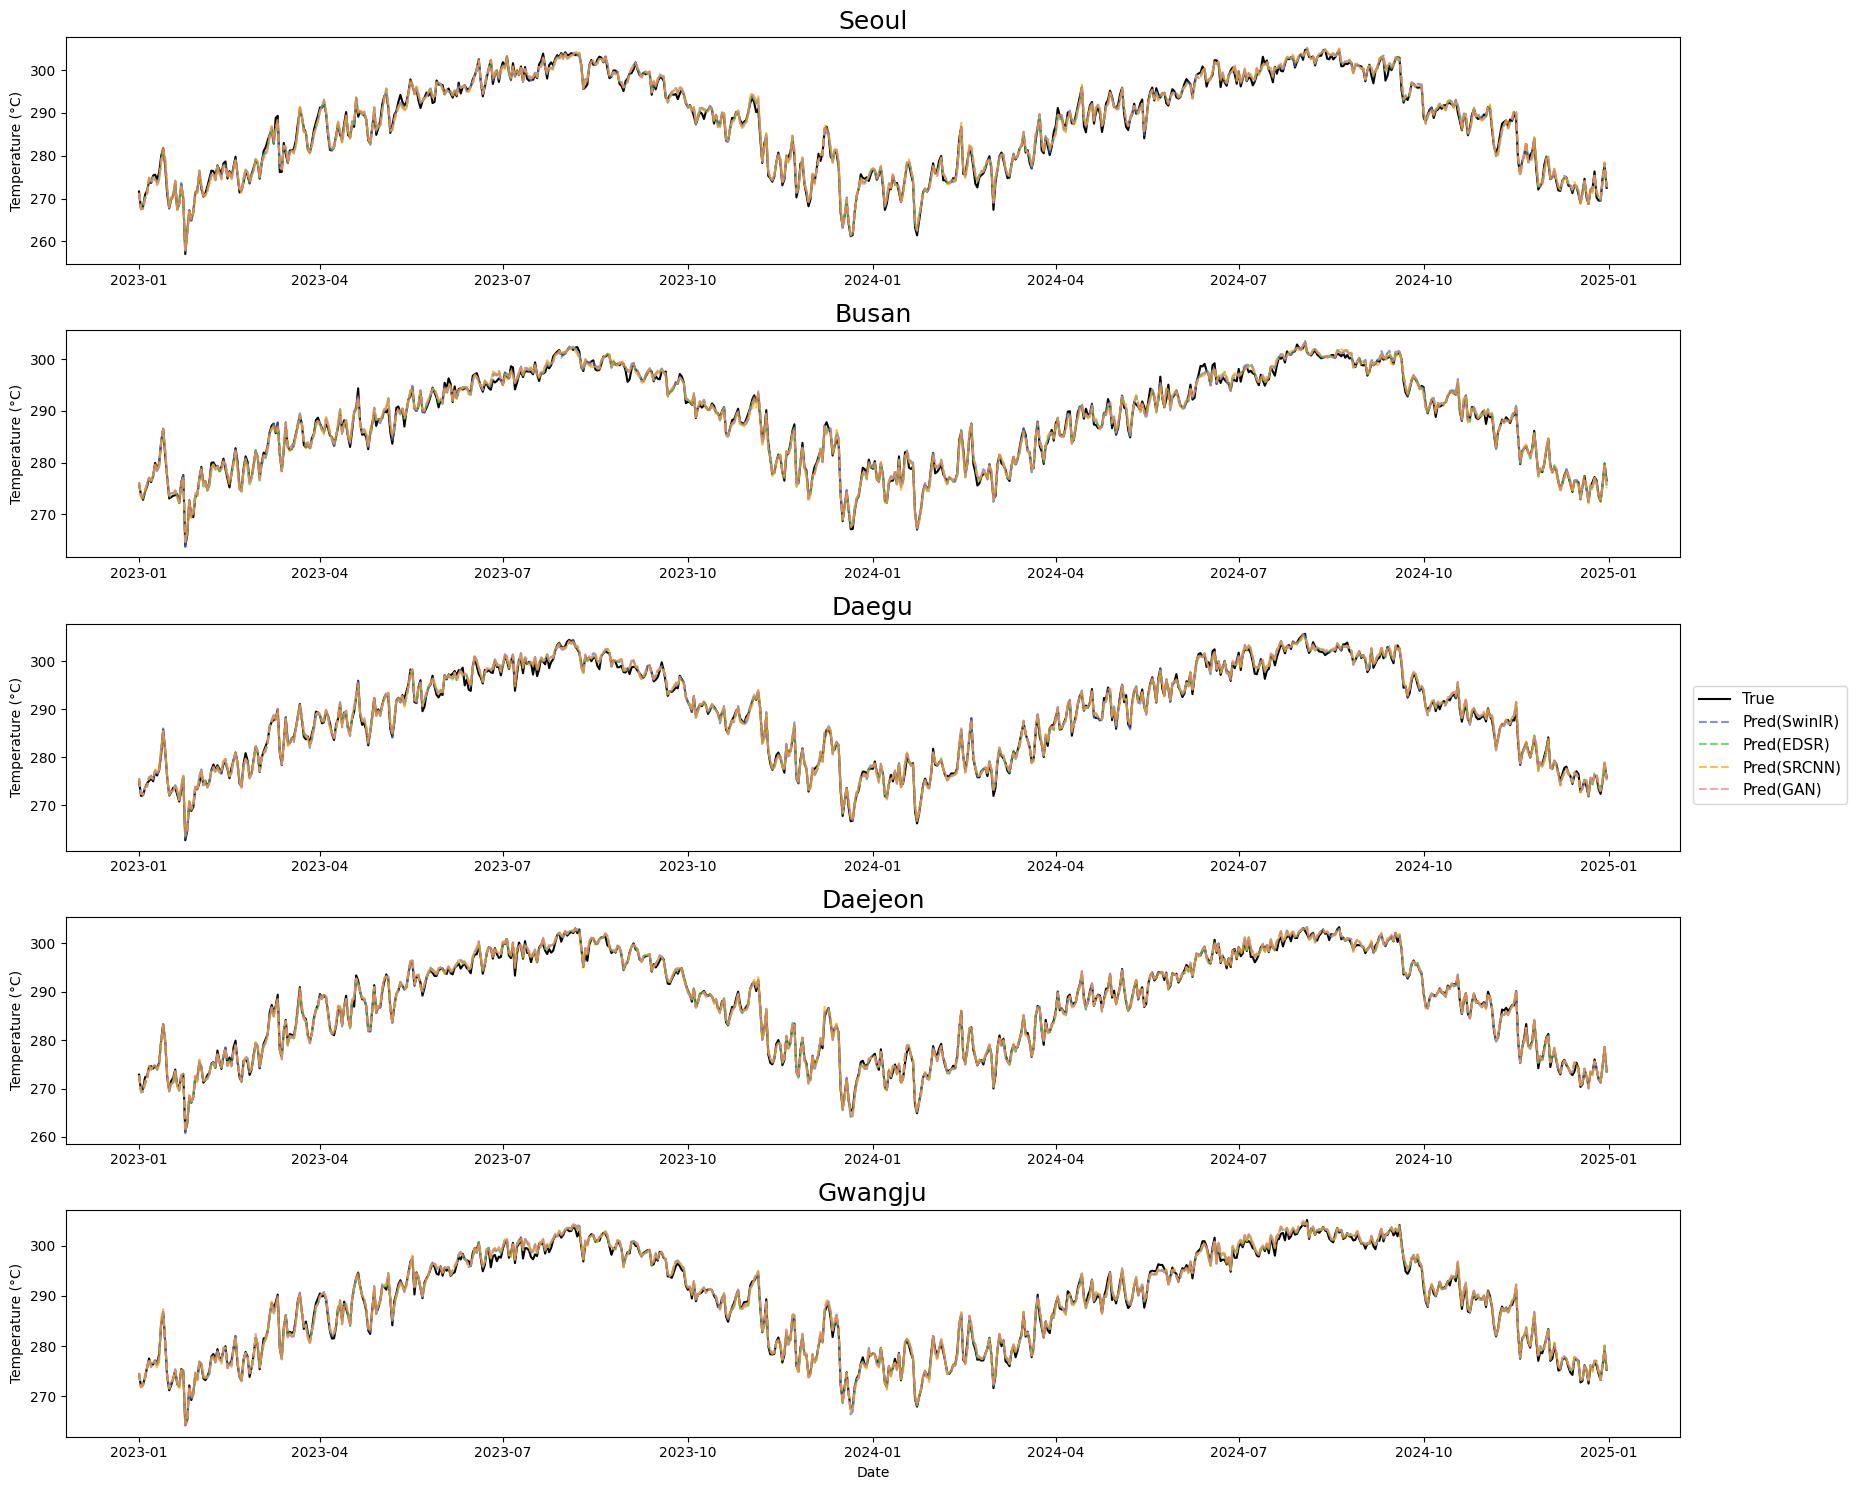

서울:
  RMSE    -> SwinIR=0.730, EDSR=0.776, SRCNN=0.881, SRGAN=0.836
  Corr    -> SwinIR=0.998, EDSR=0.997, SRCNN=0.997, SRGAN=0.997
부산:
  RMSE    -> SwinIR=0.621, EDSR=0.606, SRCNN=0.693, SRGAN=0.612
  Corr    -> SwinIR=0.998, EDSR=0.998, SRCNN=0.997, SRGAN=0.998
대구:
  RMSE    -> SwinIR=0.619, EDSR=0.592, SRCNN=0.600, SRGAN=0.640
  Corr    -> SwinIR=0.998, EDSR=0.998, SRCNN=0.998, SRGAN=0.998
대전:
  RMSE    -> SwinIR=0.530, EDSR=0.515, SRCNN=0.514, SRGAN=0.543
  Corr    -> SwinIR=0.999, EDSR=0.999, SRCNN=0.999, SRGAN=0.999
광주:
  RMSE    -> SwinIR=0.617, EDSR=0.580, SRCNN=0.656, SRGAN=0.635
  Corr    -> SwinIR=0.998, EDSR=0.998, SRCNN=0.998, SRGAN=0.998


In [ ]:
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

fig, axs = plt.subplots(nrows=5, ncols=1, figsize=(20, 15))
rmse_dict = {}
corr_dict = {}

for i, (kor_name, eng_name) in enumerate(name_map.items()):
    df_city = selected.filter(pl.col("지점명") == kor_name).sort("date")
    dates = df_city["date"].to_numpy()
    obs = df_city["평균기온(°C)"].to_numpy()
    
    iy, ix = station_indices[eng_name]
    tr = true_p3[:, iy, ix]
    pr = swinir_p3[:, iy, ix]
    pr_1 = edsr_p3[:, iy, ix]
    pr_2 = srcnn_p3[:, iy, ix]
    pr_3 = gan_p3[:, iy, ix]

    # ✅ NaN 마스킹
    valid = ~np.isnan(tr)
    tr_valid = tr[valid]
    pr_list = [pr[valid], pr_1[valid], pr_2[valid], pr_3[valid]]

    # ✅ RMSE 계산
    rmse_list = [np.sqrt(mean_squared_error(tr_valid, pred)) for pred in pr_list]
    rmse_dict[kor_name] = rmse_list

    # ✅ Correlation 계산
    corr_list = [pearsonr(tr_valid, pred)[0] for pred in pr_list]
    corr_dict[kor_name] = corr_list

    # ✅ 그래프
    ax = axs[i]
    ax.plot(dates, tr, label="True", linestyle="-", color="black")
    ax.plot(dates, pr, label="Pred(SwinIR)", linestyle="--", alpha=0.7, color=colors[0])
    ax.plot(dates, pr_1, label="Pred(EDSR)", linestyle="--", alpha=0.7, color=colors[1])
    ax.plot(dates, pr_2, label="Pred(SRCNN)", linestyle="--", alpha=0.7, color=colors[2])
    ax.plot(dates, pr_3, label="Pred(GAN)", linestyle="--", alpha=0.7, color=colors[3])

    ax.set_title(f"{eng_name}", fontsize=18)
    ax.set_ylabel("Temperature (°C)")
    #ax.axhline(y=0, color='dimgrey', alpha=0.8, ls=":")
    #ax.set_xlim(dates[0], dates[200])

axs[-1].set_xlabel("Date")
lines, labels = axs[0].get_legend_handles_labels()
fig.legend(lines, labels, loc='center right', bbox_to_anchor=(0.93, 0.5), fontsize=11)
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()


for city in rmse_dict:
    rmse = rmse_dict[city]
    corr = corr_dict[city]
    print(f"{city}:")
    print(f"  RMSE    -> SwinIR={rmse[0]:.3f}, EDSR={rmse[1]:.3f}, SRCNN={rmse[2]:.3f}, SRGAN={rmse[3]:.3f}")
    print(f"  Corr    -> SwinIR={corr[0]:.3f}, EDSR={corr[1]:.3f}, SRCNN={corr[2]:.3f}, SRGAN={corr[3]:.3f}")

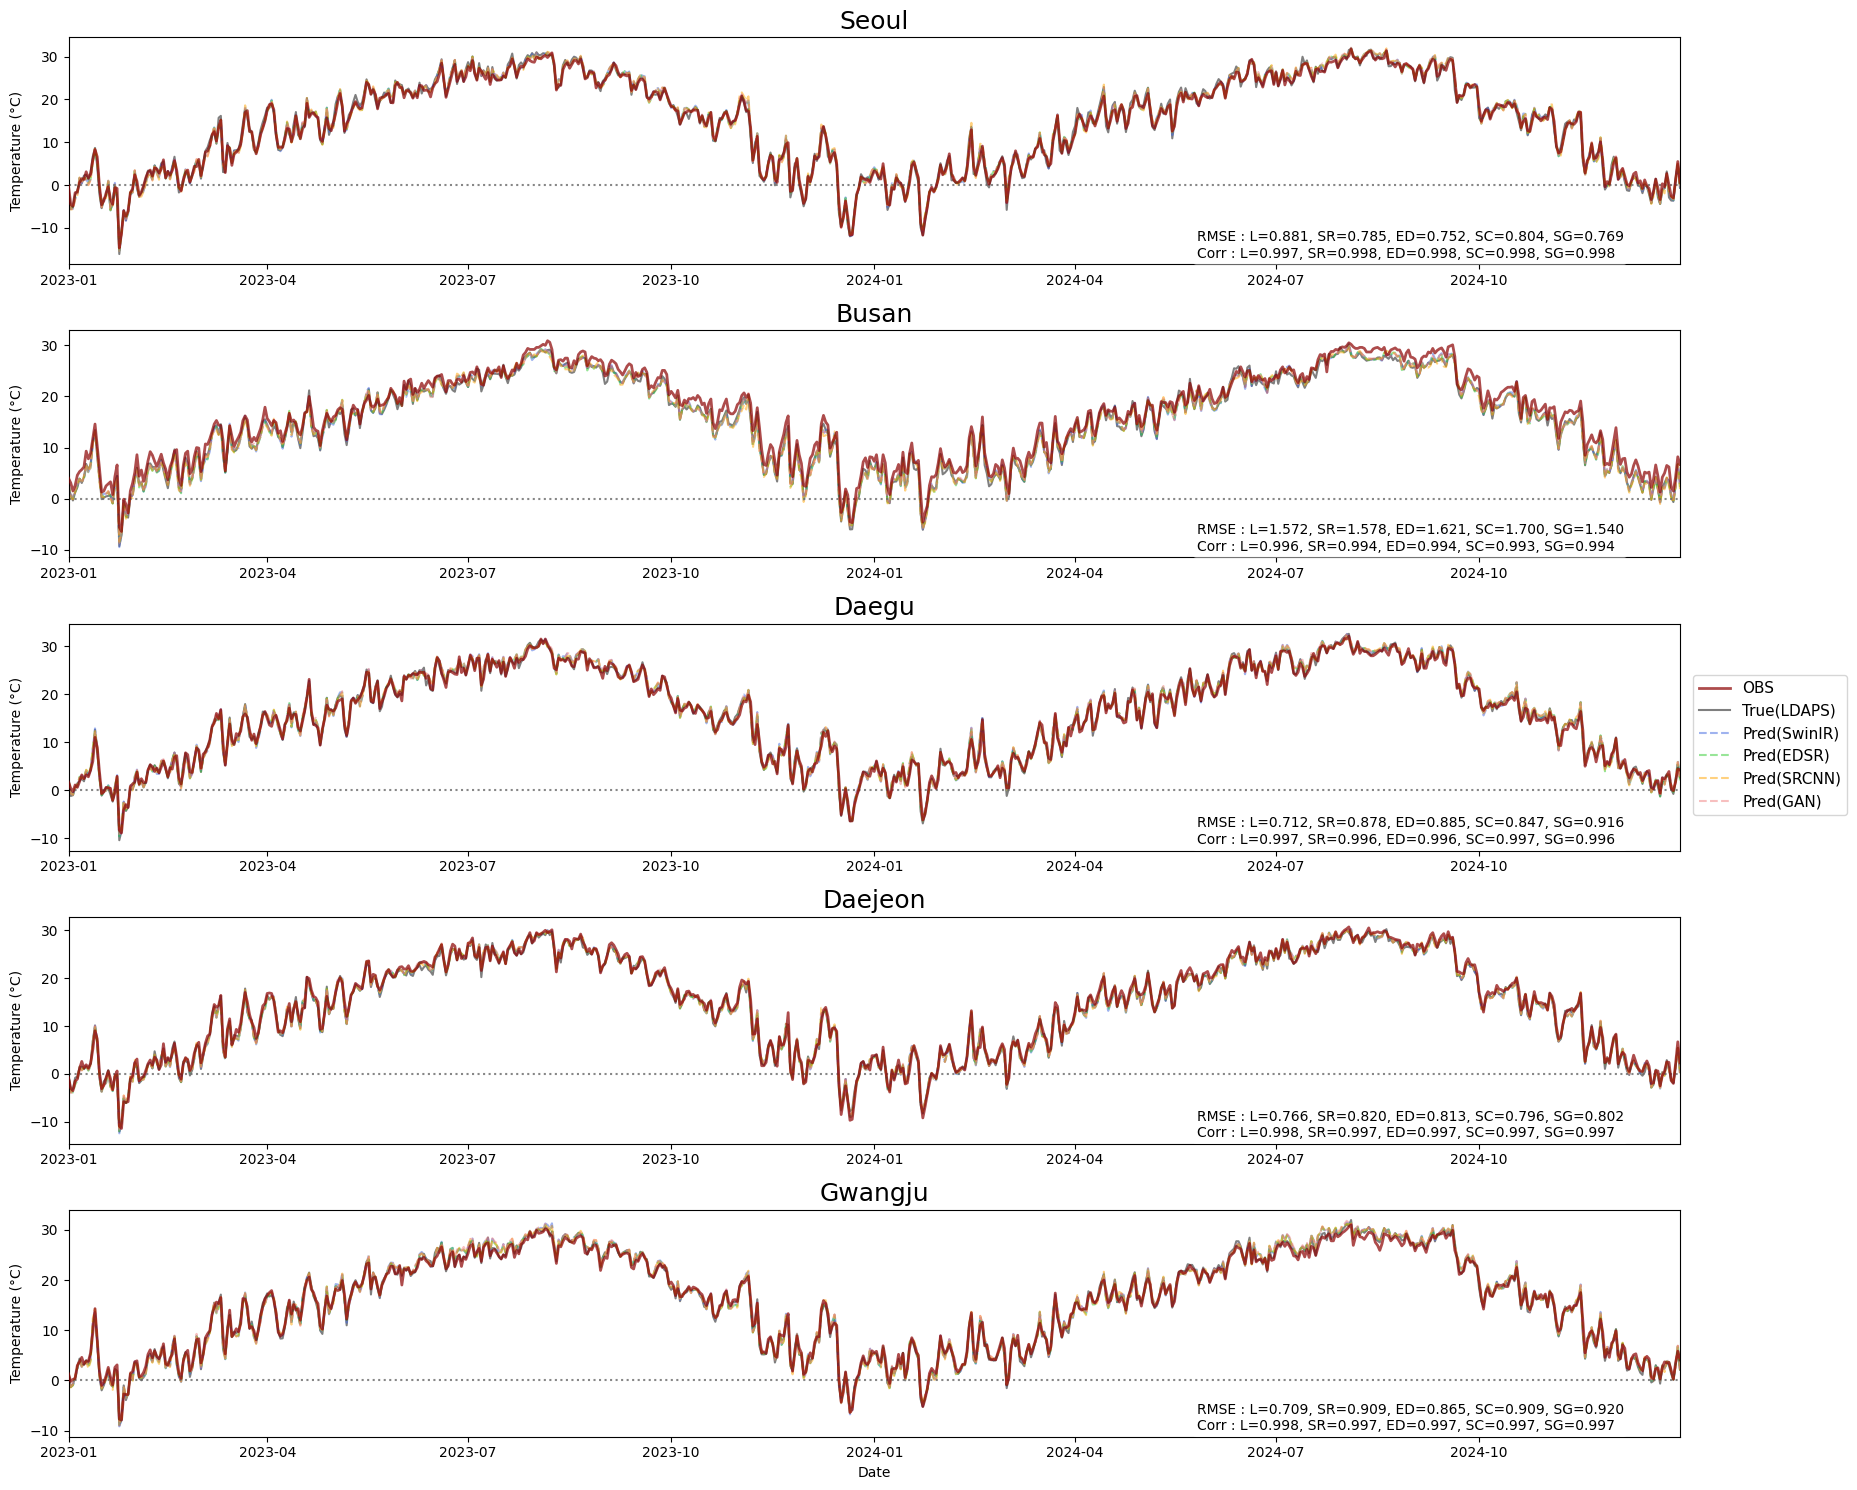

In [93]:
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

fig, axs = plt.subplots(nrows=5, ncols=1, figsize=(20, 15))
rmse_dict = {}
corr_dict = {}

for i, (kor_name, eng_name) in enumerate(name_map.items()):
    df_city = selected.filter(pl.col("지점명") == kor_name).sort("date")
    dates = df_city["date"].to_numpy()
    obs = df_city["평균기온(°C)"].to_numpy()

    iy, ix = station_indices[eng_name]
    tr = true_p3[:, iy, ix]-273.15
    pr = swinir_p3[:, iy, ix]-273.15
    pr_1 = edsr_p3[:, iy, ix]-273.15
    pr_2 = srcnn_p3[:, iy, ix]-273.15
    pr_3 = gan_p3[:, iy, ix]-273.15

    # ✅ NaN 마스킹
    valid = ~np.isnan(obs)
    obs_valid= obs[valid]
    pr_list = [tr[valid],pr[valid], pr_1[valid], pr_2[valid], pr_3[valid]]

    # ✅ RMSE 계산
    rmse_list = [np.sqrt(mean_squared_error(obs_valid, pred)) for pred in pr_list]
    rmse_dict[kor_name] = rmse_list

    # ✅ Correlation 계산
    corr_list = [pearsonr(obs_valid, pred)[0] for pred in pr_list]
    corr_dict[kor_name] = corr_list

    # ✅ 그래프
    ax = axs[i]
    ax.plot(dates, obs, label="OBS", linestyle="-", color="darkred", alpha=0.7, linewidth=2,zorder=3)
    ax.plot(dates, tr, label="True(LDAPS)", linestyle="-", color='k', alpha=0.5)
    ax.plot(dates, pr, label="Pred(SwinIR)", linestyle="--", alpha=0.5, color=colors[0])
    ax.plot(dates, pr_1, label="Pred(EDSR)", linestyle="--", alpha=0.5, color=colors[1])
    ax.plot(dates, pr_2, label="Pred(SRCNN)", linestyle="--", alpha=0.5, color=colors[2])
    ax.plot(dates, pr_3, label="Pred(GAN)", linestyle="--", alpha=0.5, color=colors[3])

    ax.set_title(f"{eng_name}", fontsize=18)
    ax.set_ylabel("Temperature (°C)")
    ax.axhline(y=0, color='dimgrey', alpha=0.8, ls=":")
    ax.set_xlim(dates[0], dates[-1])
    
    text_str = (
    f"RMSE : L={rmse_list[0]:.3f}, SR={rmse_list[1]:.3f}, ED={rmse_list[2]:.3f}, SC={rmse_list[3]:.3f}, SG={rmse_list[4]:.3f}\n"
    f"Corr : L={corr_list[0]:.3f}, SR={corr_list[1]:.3f}, ED={corr_list[2]:.3f}, SC={corr_list[3]:.3f}, SG={corr_list[4]:.3f}"
    )
    ax.text(
        0.7, 0.15, text_str,
        transform=ax.transAxes,
        fontsize=10, va="top", ha="left",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", boxstyle="round,pad=0.3")
    )

axs[-1].set_xlabel("Date")
lines, labels = axs[0].get_legend_handles_labels()
fig.legend(lines, labels, loc='center right', bbox_to_anchor=(0.93, 0.5), fontsize=11)
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()


# for city in rmse_dict:
#     rmse = rmse_dict[city]
#     corr = corr_dict[city]
#     print(f"{city}:")
#     print(f"  RMSE    -> LDAPS={rmse[0]:.3f}, SwinIR={rmse[1]:.3f}, EDSR={rmse[2]:.3f}, SRCNN={rmse[3]:.3f}, SRGAN={rmse[4]:.3f}")
#     print(f"  Corr    -> LDAPS={corr[0]:.3f}, SwinIR={corr[1]:.3f}, EDSR={corr[2]:.3f}, SRCNN={corr[3]:.3f}, SRGAN={corr[4]:.3f}")

10.546252216054476
8.425133180495454
9.55771538033842
10.085038326093711
9.253939833062192


/tmp/ipykernel_3253791/3670762859.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1])


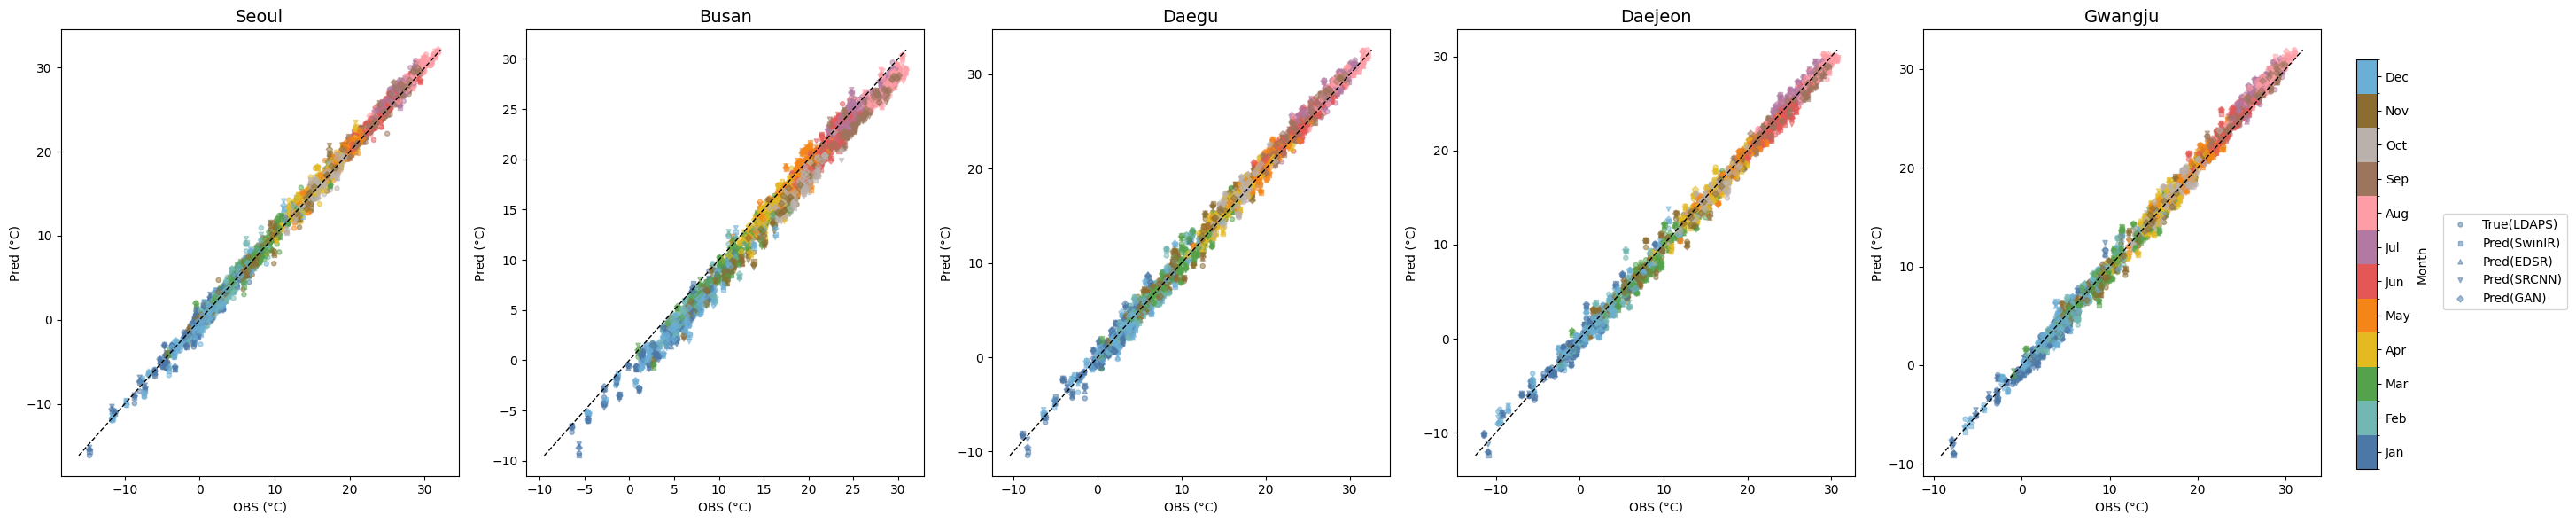

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import calendar

model_labels  = ["True(LDAPS)", "Pred(SwinIR)", "Pred(EDSR)", "Pred(SRCNN)", "Pred(GAN)"]
model_markers = ["o", "s", "^", "v", "D"]

# 12개월 색상(원하는 팔레트로 교체 가능)
month_colors = [
    "#4C78A8","#72B7B2","#54A24B","#E3BA22","#F58518","#E45756",
    "#B279A2","#FF9DA6","#9D755D","#BAB0AC","#8C6D31","#6BAED6"
]
month_labels = [calendar.month_abbr[m] for m in range(1,13)]  # ['Jan',...,'Dec']
cmap = mcolors.ListedColormap(month_colors)
bounds = np.arange(0.5, 12.5+1, 1)  # 0.5,1.5,...,12.5
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig, axs = plt.subplots(nrows=1, ncols=5, figsize=(30, 6))

for i, (kor_name, eng_name) in enumerate(name_map.items()):
    df_city = selected.filter(pl.col("지점명") == kor_name).sort("date")
    dates = df_city["date"].to_numpy()
    obs   = df_city["평균기온(°C)"].to_numpy()
    
    iy, ix = station_indices[eng_name]
    tr   = true_p3[:, iy, ix]  - 273.15
    pr   = swinir_p3[:, iy, ix]- 273.15
    pr_1 = edsr_p3[:, iy, ix]  - 273.15
    pr_2 = srcnn_p3[:, iy, ix] - 273.15
    pr_3 = gan_p3[:, iy, ix]   - 273.15

    valid      = ~np.isnan(obs)
    obs_valid  = obs[valid]
    #print(obs_valid.std())
    date_valid = dates[valid]
    pr_list    = [tr[valid], pr[valid], pr_1[valid], pr_2[valid], pr_3[valid]]

    # 월(1~12) 추출
    months = np.array([d.astype('datetime64[M]').astype(int) % 12 + 1 for d in date_valid])

    ax = axs[i]
    for pred, label, marker in zip(pr_list, model_labels, model_markers):
        ax.scatter(
            obs_valid, pred, s=14, alpha=0.5, label=label, marker=marker,
            c=months, cmap=cmap, norm=norm
        )

    # 1:1 기준선
    min_val = float(min(obs_valid.min(), *(p.min() for p in pr_list)))
    max_val = float(max(obs_valid.max(), *(p.max() for p in pr_list)))
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1)

    ax.set_title(f"{eng_name}", fontsize=14)
    ax.set_xlabel("OBS (°C)")
    ax.set_ylabel("Pred (°C)")

# 모델 범례
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center right', bbox_to_anchor=(0.97, 0.5), fontsize=10)

# 월 범례(컬러바)
sm = cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
cbar = fig.colorbar(sm, ax=axs, orientation="vertical", fraction=0.015, pad=0.02)
cbar.set_ticks(np.arange(1,13))
cbar.set_ticklabels(month_labels)  # Jan~Dec
cbar.set_label("Month")

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()


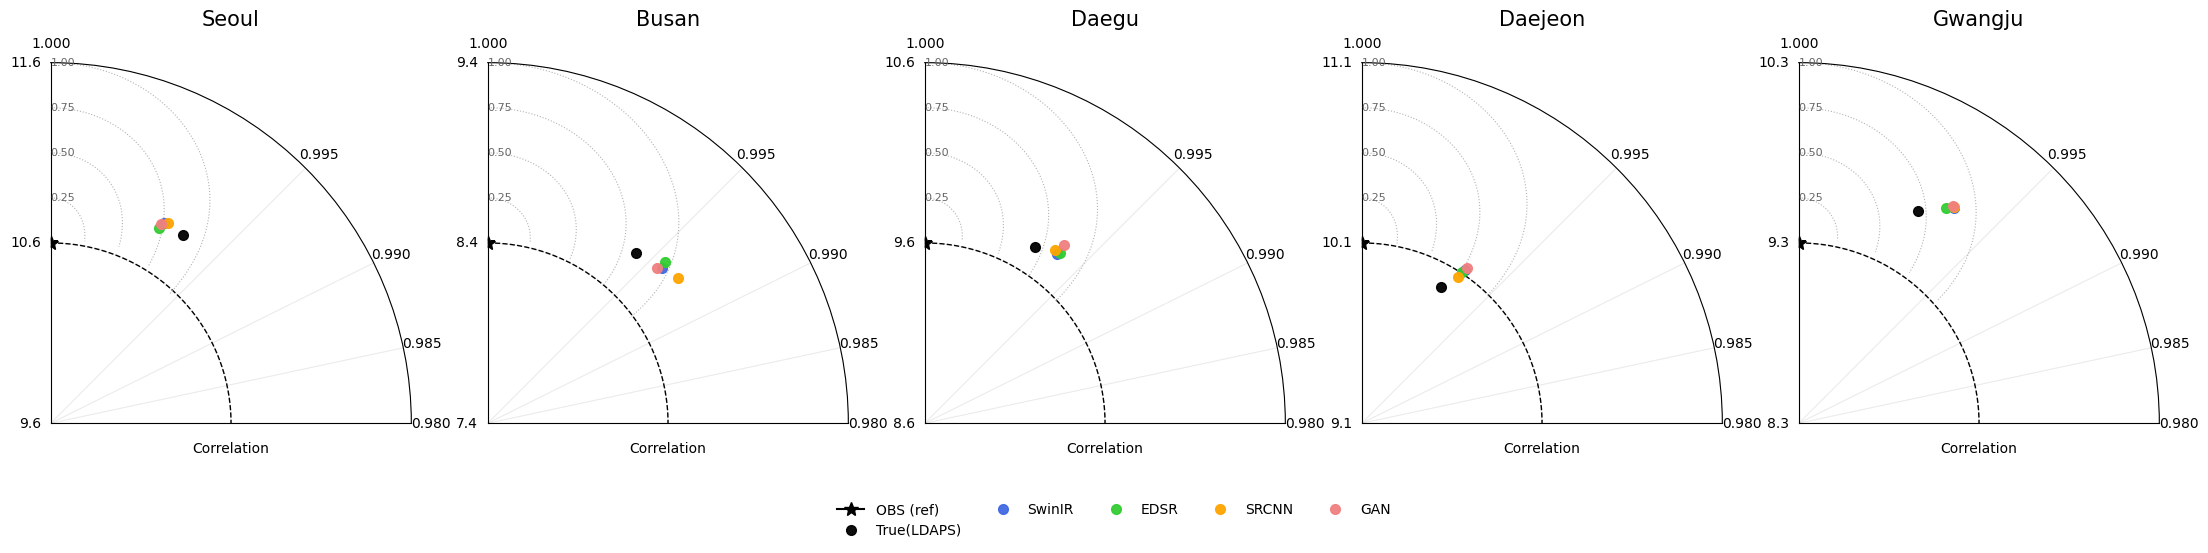

In [124]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# =========================
# Taylor diagram (90° arc, remapped to corr 1.0~min_corr)
# =========================
class TaylorDiagram:
    """
    - 표시각 φ는 항상 0~π/2(90°)로 유지
    - corr=1.0..min_corr 범위를 φ=0..π/2로 선형 확장해서 배치
      (θ_phys = arccos(corr), φ = θ_phys / arccos(min_corr) * (π/2))
    - r축은 표준편차
    - 등고선은 Centered-RMSD
    """
    def __init__(self, ref_std, ax=None, fig=None,
                 min_corr=0.95,
                 corr_ticks=(0.98,0.985,0.99,0.995, 1.00),
                 rmsd_levels=(0.5, 1.0, 1.5, 2.0),
                 std_pad=2.0):
        self.ref = float(ref_std)
        self.min_corr = float(min_corr)
        self.corr_ticks = tuple(corr_ticks)
        self.rmsd_levels = tuple(rmsd_levels)
        self.std_pad = float(std_pad)

        if fig is None: fig = plt.figure(figsize=(4,4))
        if ax  is None: ax  = fig.add_subplot(111, polar=True)
        self.fig, self.ax = fig, ax

        # ----- 각도 재매핑 -----
        self.theta_max = float(np.arccos(np.clip(self.min_corr, -1, 1)))  # 물리각 최대(=corr 하한)
        self.scale = (np.pi/2) / self.theta_max                            # φ = scale * θ_phys
        self.phys2disp = lambda th: self.scale * th                        # helper

        # polar 기본 설정
        self.ax.set_theta_zero_location("E")    # corr=1이 오른쪽
        self.ax.set_theta_direction(-1)         # 시계 방향
        self.ax.set_thetalim(0, np.pi/2)        # 표시각은 항상 0~90°
        ax.set_theta_offset(np.pi/2)

        # ----- r(표준편차) 범위/눈금 -----
        rmin = max(0.0, self.ref - self.std_pad)
        rmax = self.ref + self.std_pad
        rticks = [t for t in [self.ref-2, self.ref-1, self.ref, self.ref+1, self.ref+2]
                  if rmin <= t <= rmax]
        self.ax.set_rlim(rmin, rmax)
        if rticks:
            self.ax.set_rticks(rticks)
            self.ax.set_yticklabels([f"{t:.1f}" for t in rticks])
        self.ax.set_rlabel_position(25)
        self.ax.grid(alpha=0.25)

        # ----- corr 눈금 (0.90~1.00 만) : 표시각으로 변환해서 배치 -----
        theta_phys = np.arccos(np.clip(np.array(self.corr_ticks), -1, 1))
        theta_disp = np.degrees(self.phys2disp(theta_phys))
        self.ax.set_thetagrids(theta_disp, labels=[f"{c:.3f}" for c in self.corr_ticks])
        self.ax.set_xlabel("Correlation", labelpad=8)

        # ----- 기준 표준편차 (원 & 점) -----
        th_phys = np.linspace(0, self.theta_max, 512)
        th_disp = self.phys2disp(th_phys)
        self.ax.plot(th_disp, np.full_like(th_disp, self.ref), ls="--", color="k", lw=1)
        self.ax.plot([0], [self.ref], marker='*', color='k', ms=10, label="OBS (ref)")

        # ----- Centered-RMSD 등고선 (φ 축에 그림) -----
        cos_t = np.cos(th_phys)
        for L in self.rmsd_levels:
            disc = L**2 - (self.ref**2)*(1 - cos_t**2)   # = L^2 - σ_ref^2 sin^2θ
            disc[disc < 0] = np.nan
            r = self.ref*cos_t + np.sqrt(disc)
            self.ax.plot(th_disp, r, color="0.7", lw=0.8, ls=":")
            # 등고선 라벨(표시각의 70% 지점)
            j = int(0.7 * (len(th_disp)-1))
            if np.isfinite(r[j]):
                self.ax.text(th_disp[j], r[j], f"{L:.1f}", color="0.5", fontsize=8)
            if np.isfinite(r[0]):
                self.ax.text(th_disp[0], r[0], f"{L:.2f}",
                     color="0.4", fontsize=8,
                     ha="left", va="center")

    def add_point(self, std, corr, label, color, marker="o", ms=7, alpha=0.95):
        if not (np.isfinite(std) and np.isfinite(corr)): 
            return
        theta_phys = float(np.arccos(np.clip(corr, -1, 1)))
        # corr이 min_corr 미만이면 가장자리(φ=90°)로 클램프
        if theta_phys > self.theta_max:
            theta_phys = self.theta_max
        theta_disp = self.phys2disp(theta_phys)
        self.ax.plot(theta_disp, std, marker=marker, ls="", color=color, ms=ms, alpha=alpha, label=label)

# =========================
# 1×5 Taylor row (reference = OBS)
# =========================
def plot_taylor_row_5(name_map, selected, station_indices,
                      true_p3, swinir_p3, edsr_p3, srcnn_p3, gan_p3,
                      colors=("k","royalblue","limegreen","orange","lightcoral"),
                      min_corr=0.95, rmsd_levels=(0.5,1.0,1.5,2.0), std_pad=2.0):
    """
    name_map: {한글지점명: 영문지점명}
    selected: polars DataFrame (columns: '지점명','date','평균기온(°C)')
    station_indices: {영문지점명: (iy, ix)}
    *_p3: (T,H,W) in Kelvin
    """
    model_labels = ["True(LDAPS)","SwinIR","EDSR","SRCNN","GAN"]
    model_arrays = [true_p3, swinir_p3, edsr_p3, srcnn_p3, gan_p3]

    fig, axes = plt.subplots(1, 5, figsize=(22, 4.8), subplot_kw=dict(polar=True))

    for ax, (kor_name, eng_name) in zip(axes, name_map.items()):
        # 관측(도시) 시계열
        df_city = selected.filter(pl.col("지점명") == kor_name).sort("date")
        obs = df_city["평균기온(°C)"].to_numpy()
        valid = ~np.isnan(obs)
        obs_v = obs[valid]

        # 모델(도시) 시계열 (K -> °C)
        iy, ix = station_indices[eng_name]
        preds_v = [(arr[:, iy, ix] - 273.15)[valid] for arr in model_arrays]

        ref_std = np.nanstd(obs_v, ddof=1)

        # Taylor 생성 (90° 유지 / corr 1.0~min_corr로 확장)
        td = TaylorDiagram(ref_std, ax=ax, fig=fig,
                           min_corr=min_corr,
                           rmsd_levels=rmsd_levels,
                           std_pad=std_pad)

        # 각 모델 점 추가
        for lab, pred, col in zip(model_labels, preds_v, colors):
            std  = np.nanstd(pred, ddof=1)
            corr = pearsonr(obs_v, pred)[0] if np.nanstd(pred) > 0 else np.nan
            td.add_point(std, corr, label=lab, color=col)

        ax.set_title(f"{eng_name}", fontsize=15, y=1.08)

    # 공통 범례
    handles, labels = axes[-1].get_legend_handles_labels()
    #fig.legend( loc="lower center", ncol=5, frameon=False)
    fig.legend(handles, labels,loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.1),frameon=False)
    plt.tight_layout(rect=[0, 0.12, 1, 0.98])
    plt.show()

# =========================
# 호출 예시
# =========================
plot_taylor_row_5(
    name_map, selected, station_indices,
    true_p3, swinir_p3, edsr_p3, srcnn_p3, gan_p3,
    colors=("k","royalblue","limegreen","orange","lightcoral"),
    min_corr=0.98,          # ← 여기만 바꾸면 0.92~1.00 등으로도 볼 수 있음
    rmsd_levels=(0.25, 0.5, 0.75, 1.0),
    std_pad=1.0
)


### Target Data distrubtion 확인

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 도시 및 모델 이름
cities = ["Seoul", "Busan", "Daegu", "Daejeon", "Gwangju"]
models = ["EDSR", "SRCNN", "GAN", "SwinIR"]

# 상관계수 데이터
correlations = {
    "Seoul": [0.826, 0.782, 0.732, 0.796],
    "Busan": [0.824, 0.770, 0.702, 0.824],
    "Daegu": [0.824, 0.778, 0.714, 0.799],
    "Daejeon": [0.822, 0.774, 0.705, 0.800],
    "Gwangju": [0.809, 0.761, 0.726, 0.795],
}

# 도시별 색상 지정 (고정 순서)
colors = ['tomato', 'salmon',  'orange', 'mediumseagreen', 'skyblue']

# 모델별로 도시 성능을 막대그래프로 표시
x = np.arange(len(models))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(10, 6))

for i, (city, color) in enumerate(zip(cities, colors)):
    scores = [correlations[city][j] for j in range(len(models))]
    ax.bar(x + i * bar_width, scores, bar_width, label=city, alpha=0.85, color=color)

# 시각적 설정
ax.set_xticks(x + bar_width * (len(cities) - 1) / 2)
ax.set_xticklabels(models, fontsize=12)
ax.set_ylim(0, 1)
ax.set_ylabel("Correlation", fontsize=13)
ax.set_title("Correlation by Model across Cities", fontsize=15)
ax.legend(title="City")

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 이전 루프에서 계산된 예시 RMSE 값 (실제 코드에서는 rmse_dict에 저장됨)
rmse_dict = {
    "Seoul": [1.31, 1.45, 1.62, 1.34],
    "Busan": [1.29, 1.42, 1.68, 1.31],
    "Daegu": [1.34, 1.48, 1.60, 1.36],
    "Daejeon": [1.32, 1.44, 1.63, 1.35],
    "Gawangju": [1.37, 1.50, 1.61, 1.38],
}

cities = list(rmse_dict.keys())
models = ["EDSR", "SRCNN", "GAN", "SwinIR"]
x = np.arange(len(models))
bar_width = 0.15
colors = ['tomato', 'salmon',  'orange', 'mediumseagreen', 'skyblue']

fig, ax = plt.subplots(figsize=(10, 6))
for i, (city,color) in enumerate(zip(cities,colors)):
    ax.bar(x + i * bar_width, rmse_dict[city], bar_width, label=city, alpha=0.85, color=color)

ax.set_xticks(x + bar_width * (len(cities) - 1) / 2)
ax.set_xticklabels(models, fontsize=12)
ax.set_ylabel("RMSE (K)", fontsize=13)
ax.set_title("RMSE by Model", fontsize=15)
ax.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

station_indices = {
    'Seoul': (333, 178),
    'Busan': (157, 303),
    'Daegu': (212, 279),
    'Daejeon': (246, 203),
    'Gwangju': (159, 176)
}

#true_anom = torch.load("../Data/Dataset/target_tmpr_data_monthly.pt")
time = pd.date_range(start="2013-01-01", periods=true_anom.shape[0], freq="D")
val_mask = (time >= "2021-01-01") & (time <= "2022-12-31")
test_mask = (time >= "2023-01-01") & (time <= "2024-12-31")
train_mask = ~val_mask & ~test_mask

fig, axs = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, (name, (y, x)) in enumerate(station_indices.items()):
    ts = true_anom[:, y, x].numpy()

    train_ts = ts[train_mask]
    val_ts = ts[val_mask]
    test_ts = ts[test_mask]

    axs[i].hist(train_ts, bins=50, alpha=0.6, label="Train", color="cornflowerblue")
    axs[i].hist(val_ts, bins=50, alpha=0.6, label="Val", color="sandybrown")
    axs[i].hist(test_ts, bins=50, alpha=0.6, label="Test", color="seagreen")
    axs[i].axvline(0, color='k', linestyle='--')
    axs[i].set_title(name)
    axs[i].set_xlabel("Anomaly (°C)")
    
    # 평균 및 표준편차 출력 텍스트
    stats_text = (       "       μ          σ\n "
        f"Train: {train_ts.mean():+.2f},  {train_ts.std():.2f}\n"
        f"Vald: {val_ts.mean():+.2f},  {val_ts.std():.2f}\n"
        f"Test: {test_ts.mean():+.2f}, {test_ts.std():.2f}"
    )
    axs[i].text(0.02, 0.95, stats_text, transform=axs[i].transAxes,
                fontsize=9, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.6))

    if i == 0:
        axs[i].set_ylabel("#")

axs[0].legend()
plt.suptitle("Temperature  Distribution by Station (Train/Val/Test)")
plt.tight_layout()
plt.show()


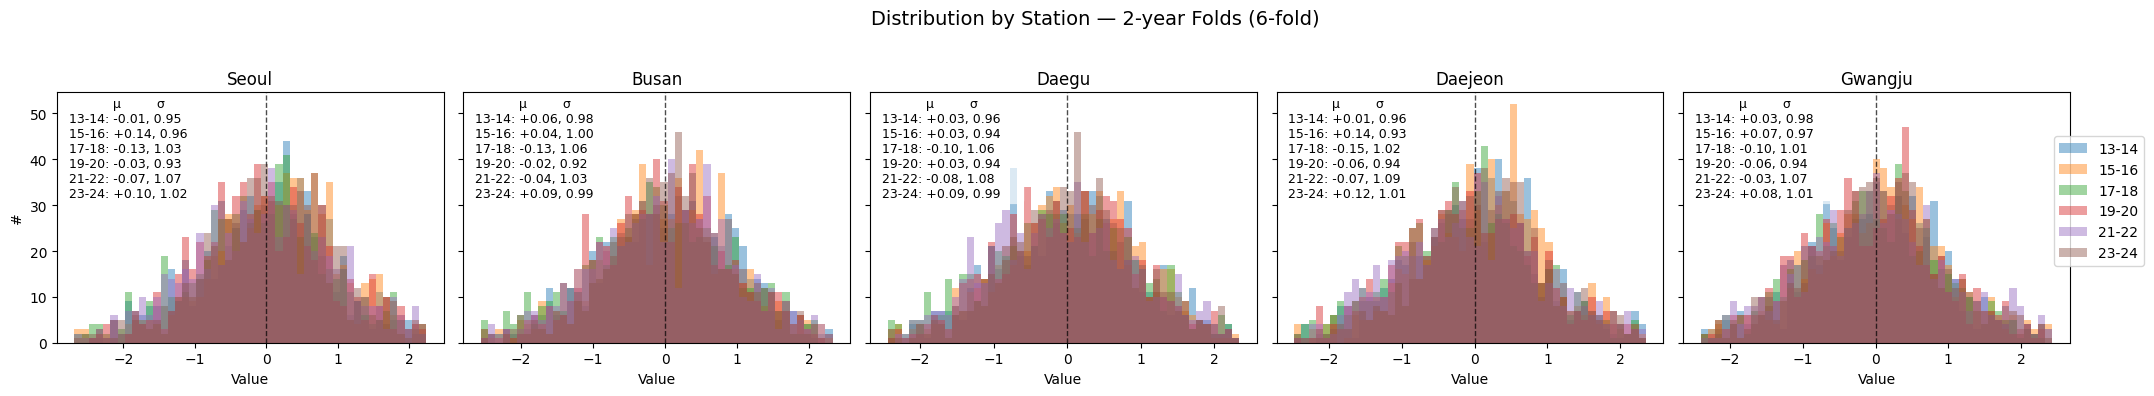

In [35]:
time = pd.date_range(start="2013-01-01", periods=true_anom.shape[0], freq="D")

# 2년 단위 fold 정의 (앞→뒤 순서)
fold_years = [(2013,2014), (2015,2016), (2017,2018), (2019,2020), (2021,2022), (2023,2024)]
fold_labels = ["13-14", "15-16","17-18", "19-20", "21-22","23-24"]
fold_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]  # 구분용 색

# 마스크 미리 계산
fold_masks = []
for (y1, y2) in fold_years:
    m = (time >= f"{y1}-01-01") & (time <= f"{y2}-12-31")
    fold_masks.append(m)

fig, axs = plt.subplots(1, len(station_indices), figsize=(22, 4), sharey=True)

# 스테이션 루프
for i, (name, (y, x)) in enumerate(station_indices.items()):
    # (T,) numpy 시계열
    ts = true_anom[:, y, x].detach().cpu().numpy() if isinstance(true_anom, torch.Tensor) else np.asarray(true_anom[:, y, x])

    # NaN 제거를 위해 전체 valid 먼저 파악(히스토그램 bin 범위 산정용)
    ts_valid = ts[np.isfinite(ts)]
    if ts_valid.size == 0:
        # 데이터가 전부 NaN이면 스킵
        axs[i].set_title(name)
        axs[i].set_xlabel("Value")
        if i == 0:
            axs[i].set_ylabel("#")
        continue

    # 공정 비교를 위해 스테이션별 공통 bins 지정(1~99 퍼센타일 범위 권장)
    lo = np.nanpercentile(ts_valid, 1)
    hi = np.nanpercentile(ts_valid, 99)
    if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:
        lo, hi = np.nanmin(ts_valid), np.nanmax(ts_valid)
    bins = np.linspace(lo, hi, 50)

    # fold별 통계 저장용
    means, stds = [], []

    # 히스토그램 겹쳐 그리기
    ax = axs[i]
    for k, (mask, label, color) in enumerate(zip(fold_masks, fold_labels, fold_colors)):
        v = ts[mask]
        v = v[np.isfinite(v)]
        if v.size == 0:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        ax.hist(v, bins=bins, alpha=0.45, label=label, color=color)
        means.append(float(np.nanmean(v)))
        stds.append(float(np.nanstd(v)))

    ax.axvline(0, color='k', linestyle='--', linewidth=1, alpha=0.7)  # anomaly 중심선 등 필요시
    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Value")
    if i == 0:
        ax.set_ylabel("#")

    # 좌측 상단에 fold별 μ, σ 요약
    # 줄 수가 많으니 3+3 두 블록으로 나눠서 가독성 확보
    text_lines = ["            μ         σ"] + [f" {lbl}: {m:+.2f}, {s:.2f}     " for lbl, m, s in zip(fold_labels, means, stds)]
    text_block = "\n".join(text_lines)  # 상단 블록(헤더+3줄)

    ax.text(0.02, 0.98, text_block,
            transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(facecolor="white", alpha=0.65, edgecolor="none", boxstyle="round,pad=0.3"))


# 범례는 첫 축에서만 추출해서 전체에 공통 표시
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", bbox_to_anchor=(0.98, 0.5), frameon=True)

plt.suptitle("Distribution by Station — 2-year Folds (6-fold)", fontsize=14)
plt.tight_layout(rect=[0, 0, 0.95, 0.95])
plt.show()